In [16]:
%load_ext autoreload
%autoreload 2

## Imports

In [14]:
import pandas as pd
import numpy as np
import io
import networkx as nx
from math import prod

from io import StringIO
from itertools import product, combinations, permutations
from scipy.stats import pearsonr

from matplotlib import pyplot as plt
from matplotlib import rcParams
import seaborn as sns

import logging

In [3]:
logger = logging.getLogger()
#logger.setLevel(logging.DEBUG)
logger.setLevel(logging.INFO)

In [4]:
from utils.utils import visualise_test

In [5]:
from utils.input import read_subsystems

In [19]:
from analysis.community import Community, Hegemon, analyse_local_community, detect_local_communities
from analysis.network_analysis import get_networks, countCentrality, get_network_from_year_df, plotWithPyvis
from analysis.dataset_testing import pretest_dataset, test_triple_df

from data_handling import sipri, jme, interventions, deployments, fdi, trade, hitech, energy, refugee
from data_handling import migrant, tourism, humanun, visits, peacekeep, oda, students

from analysis.hegemony import get_hegemony_scores, get_hegemony_top, visualize_hegemony
from utils.utils import get_all_countries, get_empty_country_df, get_system_members, get_percent_df, test_df
from utils.utils import test_sphere, row_geometric_mean
from utils.countryconverter import convert_country_df
from utils.df_processing import merge_sphere, normalize, remove_self_loops, show_top, to_mean

### Constant variables

In [7]:
YEAR_START=1985
YEAR_END=2022
SUBSYSTEM_WEIGHTS = {  # BY IHES 2022students-dos
    'human' : 1.79 / (1.79+2.4+3.2),
    'economy' : 2.4 / (1.79+2.4+3.2),
    'security' : 3.2 / (1.79+2.4+3.2)#,
#    'climate' : 2.64
}
#ECONOMY_WEIGHTS = {
#    'fdi':0.5,
#    'trade':0.5,
#    'hitech':0.2,
#    'energy':0.3
#}
ECONOMY_WEIGHTS = {  # IHES Wave V
    'fdi':3.27,
    'trade':2.7,
    'hitech':3.6,
    'energy':3.6
}
HUMAN_WEIGHTS = {
    'migrant':0.16,
    'refugee':0.17,
    'humanun':0.155,
    'oda':0.198,
    'students':0.14
}
SECURITY_WEIGHTS = {
    'interventions':0.13,
    'sipri':0.12,
    'deployments':0.145,
    'jme':0.1  #incorrect
}

SUBSYSTEMS = ['economy', 'security', 'human']
SUBSYSTEMS_RU = {
    'economy':'экономическая',
    'security':'безопасность',
    'human':'гуманитарная',
    'OVERALL':'мировая политика в совокупности'
}
PLOT_GREY = False
RUSSIFY_VISUALS = True
rolling_window = 5
isDigraph = True

RANKMIN=10  # Минимальный ранг в любой год, чтобы отражать страну в графике
MAXRANK=50  # Максимальный ранг, чтобы отражать ранг страны в конкретный год в графике
SPHERE='security'  #  Default sphere

### Functions

In [8]:
def analyse_system(processed_dfs, year_start, year_end, centrality_type='pagerank', print_trace=False, count_abs=False):
    # Analyzing centrality in the international system
    subsystems = {}
    centrality_data = []# sm_dyads.drop('alter', axis=1).drop_duplicates().set_index(['ego','year'])
    for subsystem in processed_dfs:
        logging.info(f"Analysing {subsystem}")
        df = processed_dfs[subsystem]
        
        df = df.reset_index()
        df['year'] = df['year'].astype(int)
        df = df.set_index(['year', 'alter', 'ego'], drop=True)
        countries_all = get_all_countries(processed_df=df.reset_index(), ego_column = 'ego', alter_column = 'alter')  # getting set of all countries
        networks = get_networks(df, countries_all, year_start=YEAR_START, 
                                year_end=YEAR_END, isDigraph=isDigraph,
                                count_abs=count_abs, print_trace=print_trace
                               )  # getting networks
        
        subsystems[subsystem] = {'data': df, 'networks':networks}
        for y in range(year_start, year_end+1):
            df_y = df.reset_index()
            df_y = df_y[df_y['year']==y]
            countries_all = set(df_y['ego']) or set(df_y['alter'])
            #countries_all = get_all_countries(processed_df=df_y.reset_index(), ego_column = 'ego', alter_column = 'alter')  # getting set of all countries
            if print_trace:
                print(y, subsystem)
            if type(centrality_type) == str:
                centrality = countCentrality(networks[y], country_list = countries_all, centrality_type=centrality_type, prefix='')
            elif type(centrality_type) == dict:  # Dict with subsystem names and centrality types
                centrality = countCentrality(networks[y], country_list = countries_all, centrality_type=centrality_type[subsystem], prefix='')
            else:
                raise TypeError(f"Expected centrality_type to be str or dict, got {type(centrality_type)} instead")
            #return centrality[0], centrality[1]
            centrality = centrality.sort_values(f'status')
            centrality['year'] = y
            centrality['subsystem'] = subsystem
            centrality_data += centrality,
    centrality_result = pd.concat(centrality_data)
    return centrality_result.reset_index().rename({'index':'ego'}, axis=1), subsystems

def combine_spheres(analysis): # Combining spheres via centrality
    
    status_combined = analysis.groupby(['ego', 'year']).sum()
    status_combined['weighted_centrality'] = status_combined['weighted_centrality'].astype(float)
    status_combined['rank_combined'] = status_combined['weighted_centrality'].groupby(['year']).rank(ascending=False, method='min')
    #status_combined['weighted_centrality'].rank(ascending=False, method='min')
    return status_combined

def visualize_sphere(analysis, rankmin=RANKMIN, maxrank=MAXRANK, sphere=SPHERE, plot_grey=PLOT_GREY, russify=RUSSIFY_VISUALS):
    # Подготовка данных
    data = analysis[analysis['subsystem']==sphere]
    if russify:
        data = convert_country_df(data, data_id_col='ego', standard_to_convert='STATE_ru', print_convertions=False)
        sphere_name = SUBSYSTEMS_RU[sphere]
    else:
        sphere_name = sphere
        
    #print(data)
    egos_top = data[data['rank']<=rankmin]['ego'].unique()
    data = data[data['ego'].isin(egos_top)]
    data = data[data['rank']<=maxrank]
    #pivot_data = data.pivot_table(index='ego', columns='year', values='rank').sort_values(YEAR_END, ascending=True)
    pivot_data = data.pivot_table(index='ego', columns='year', values='rank').sort_values(YEAR_END, ascending=True)
    plt.figure(figsize=(15, 6.5))
    if plot_grey:
        cmap = plt.get_cmap('Greys', 20)
    else:
        cmap='YlOrRd'
    sns.heatmap(pivot_data, annot=True, cmap=cmap, linewidths=1.8)
    if russify: 
        plt.xlabel('год')
        plt.ylabel('альтер')
    plt.title(f'Тепловая карта по рангу стран ({sphere_name})')
    plt.text(0.5, -0.17,  
             f"*Примечание: пустые ячейки означают ранг >{maxrank} или отсутствие данных",
             ha='left', 
             va='center', 
             transform=plt.gca().transAxes,
             fontsize=10,
             bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))
    plt.savefig(f'../output/{sphere}_ranks{"_grey" if PLOT_GREY else ""}.png', dpi=300, bbox_inches='tight')
    plt.show()

def visualize_overall(status_combined, plot_grey = PLOT_GREY, rankmin=RANKMIN, rankmax=MAXRANK, russify=RUSSIFY_VISUALS):

    SPHERE ='OVERALL'

    data = status_combined.reset_index()
    if russify:
        data = convert_country_df(data, data_id_col='ego', standard_to_convert='STATE_ru', print_convertions=False)
        SPHERE = SUBSYSTEMS_RU[SPHERE]
    egos_top = data[data['rank_combined']<=rankmin]['ego'].unique()
    data = data[data['ego'].isin(egos_top)]
    data = data[data['rank_combined']<=rankmax]
    
    pivot_data = data.pivot_table(index='ego', columns='year', values='rank_combined').sort_values(YEAR_END, ascending=True)
    
    plt.figure(figsize=(15, 6.5))
    if plot_grey:
        cmap = plt.get_cmap('Greys', 20)
    else:
        cmap='YlOrRd'
    sns.heatmap(pivot_data, annot=True, cmap=cmap, linewidths=1.8)
    plt.title(f'Тепловая карта по рангу стран ({SPHERE})')
    plt.xlim=(1992,2023)
    if russify: 
        plt.xlabel('год')
        plt.ylabel('альтер')
    plt.text(0.5, -0.17,  
             f"*Примечание: пустые ячейки означают ранг >{rankmax} или отсутствие данных",
             ha='left', 
             va='center', 
             transform=plt.gca().transAxes,
             fontsize=10,
             bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))
    plt.savefig(f'../output/{SPHERE}_ranks{"_grey" if PLOT_GREY else ""}.png', dpi=300, bbox_inches='tight')
    plt.show()

## Data preprocessing

### International security

##### Arms Trade (SIPRI)

INFO:root:Loaded SIPRI Arms Transfer Data
INFO:root:Preprocessing SIPRI Arms Transfer Data
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier Kosovo, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier Northern Cyprus, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier South Yemen, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier Western Sahara, replacing with None
  if warning: warnings.warn(f"Unkn

                                                 seller  \
odat                                                      
1985  Russian FederationRussian FederationRussian Fe...   
1986  Russian FederationRussian FederationRussian Fe...   
1987  Russian FederationRussian FederationRussian Fe...   
1988  Russian FederationRussian FederationRussian Fe...   
1989  Russian FederationRussian FederationRussian Fe...   
1990  Russian FederationRussian FederationRussian Fe...   
1991  Russian FederationRussian FederationRussian Fe...   
1992  Russian FederationRussian FederationRussian Fe...   
1993  Russian FederationRussian FederationRussian Fe...   
1994  Russian FederationRussian FederationRussian Fe...   
1995  Russian FederationRussian FederationRussian Fe...   
1996  Russian FederationRussian FederationRussian Fe...   
1997  Russian FederationRussian FederationRussian Fe...   
1998  Russian FederationRussian FederationRussian Fe...   
1999  Russian FederationRussian FederationRussian Fe... 

KeyError: 'seller'

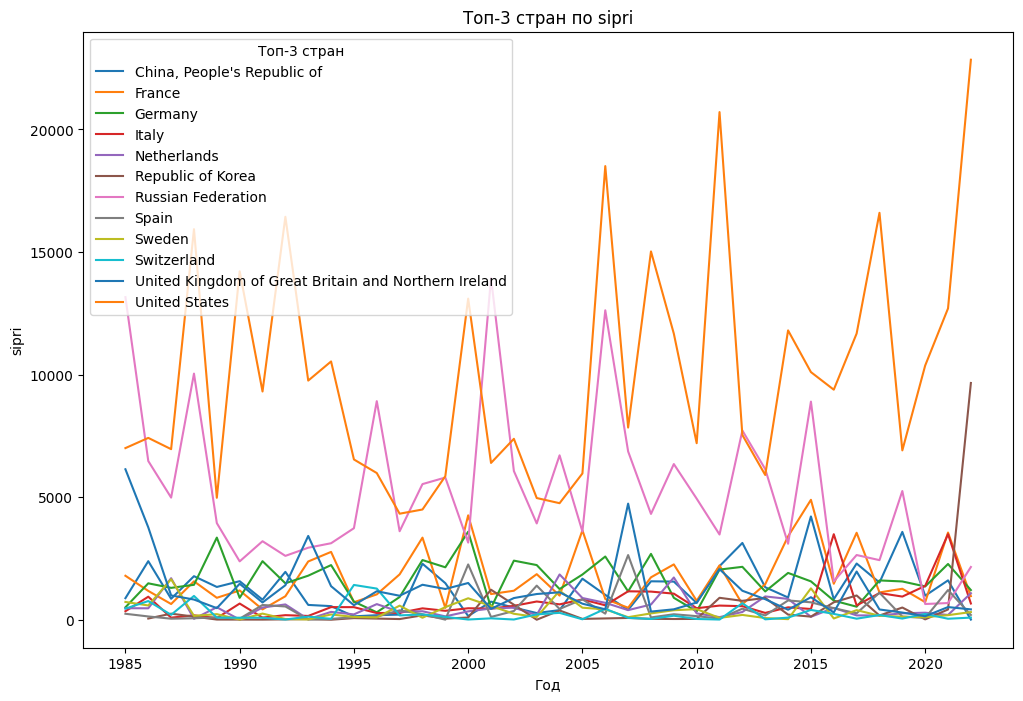

In [22]:
sipri_df = sipri.load_sipri()
sipri_df, sipri_processed_df = sipri.preprocess_sipri(sipri_df, year_start=1985, rolling_window=5)
sipri_df.to_csv("../data/basic_preprocessed/arms.csv")
sipri_processed_df.to_csv("../data/preprocessed/arms.csv")

In [17]:
sipri_df = pd.read_csv("../data/basic_preprocessed/arms.csv").drop('Unnamed: 0', axis=1)
sipri_processed_df = pd.read_csv("../data/preprocessed/arms.csv").set_index(['ego', 'alter', 'year'])

In [228]:
# Проблема: Польша продавала оружие США и СССР в один год
# Проблема: высокий показатель у Непала из-за миротворческих операций ООН - убрали операцию

##### Interventions (Correlates of military interventions)

DEBUG:data_handling.gsheet_handler:1. try:
DEBUG:root:reading google table interventions, sheet i_main
DEBUG:urllib3.connectionpool:https://www.googleapis.com:443 "GET /drive/v3/files?q=mimeType%3D%22application%2Fvnd.google-apps.spreadsheet%22+and+name+%3D+%22interventions%22&pageSize=1000&supportsAllDrives=True&includeItemsFromAllDrives=True&fields=kind%2CnextPageToken%2Cfiles%28id%2Cname%2CcreatedTime%2CmodifiedTime%29 HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1RM5ByxkVnf9TveX3v1zcMNy7o0MzSG21AvZlfXLOpgs?includeGridData=false HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1RM5ByxkVnf9TveX3v1zcMNy7o0MzSG21AvZlfXLOpgs?includeGridData=false HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1RM5ByxkVnf9TveX3v1zcMNy7o0MzSG21AvZlfXLOpgs/values/%27i_main%27?valueRenderOption=UNFORMATTED_VALUE&dateTimeRenderOption=FORMAT

740 Japan
210 Netherlands
910 Papua New Guinea
702 Tajikistan
749 None
666 Israel
800 Thailand
481 Gabon
339 Albania
404 Guinea-Bissau
255 Germany
510 United Republic of Tanzania
433 Senegal
541 Mozambique
705 Kazakhstan
439 Burkina Faso
840 Philippines
732 Republic of Korea
490 Democratic Republic of the Congo
40 Cuba
20 Canada
1016 None
451 Sierra Leone
830 Singapore
616 Tunisia
571 Botswana
2431 None
660 Lebanon
2 United States
265 German Democratic Republic
160 Argentina
49 None
1 None
560 South Africa
130 Ecuador
3903 None
750 India
651 Egypt
640 Türkiye
517 Rwanda
344 Croatia
696 United Arab Emirates
679 Yemen
692 Bahrain
698 Oman
516 Burundi
731 Democratic People's Republic of Korea
365 Russian Federation
436 Niger
93 Nicaragua
816 Viet Nam
663 Jordan
230 Spain
452 Ghana
366 Estonia
2400 None
520 Somalia
2420 None
552 Zimbabwe
2450 None
920 New Zealand
625 Sudan
369 Ukraine
690 Kuwait
530 Ethiopia
3300 None
704 Uzbekistan
317 Slovakia
135 Peru
345 Serbia
2220 None
343 Republic o

/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier 749, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier 709, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier 755, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier 1, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryco

352 Cyprus
210 Netherlands
740 Japan
935 Vanuatu
910 Papua New Guinea
702 Tajikistan
749 None
781 Maldives
666 Israel
800 Thailand
481 Gabon
581 Comoros
339 Albania
404 Guinea-Bissau
709 None
510 United Republic of Tanzania
433 Senegal
255 Germany
541 Mozambique
439 Burkina Faso
840 Philippines
755 None
490 Democratic Republic of the Congo
732 Republic of Korea
40 Cuba
451 Sierra Leone
571 Botswana
616 Tunisia
660 Lebanon
2 United States
265 German Democratic Republic
1 None
31 Bahamas
560 South Africa
130 Ecuador
750 India
651 Egypt
517 Rwanda
640 Türkiye
344 Croatia
145 Bolivia (Plurinational State of)
692 Bahrain
679 Yemen
516 Burundi
698 Oman
731 Democratic People's Republic of Korea
93 Nicaragua
365 Russian Federation
436 Niger
411 Equatorial Guinea
70 Mexico
816 Viet Nam
663 Jordan
230 Spain
520 Somalia
450 Liberia
552 Zimbabwe
395 Iceland
780 Sri Lanka
625 Sudan
110 Guyana
690 Kuwait
530 Ethiopia
940 Solomon Islands
41 Haiti
601 None
135 Peru
61 None
345 Serbia
420 Gambia
761 No

DEBUG:urllib3.connectionpool:https://www.googleapis.com:443 "GET /drive/v3/files?q=mimeType%3D%22application%2Fvnd.google-apps.spreadsheet%22+and+name+%3D+%22country_data%22&pageSize=1000&supportsAllDrives=True&includeItemsFromAllDrives=True&fields=kind%2CnextPageToken%2Cfiles%28id%2Cname%2CcreatedTime%2CmodifiedTime%29 HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1-A17WUw0EPdt2PFFJAC0F31w7I-jSCuAbmGwc9JWHnQ?includeGridData=false HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1-A17WUw0EPdt2PFFJAC0F31w7I-jSCuAbmGwc9JWHnQ?includeGridData=false HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1-A17WUw0EPdt2PFFJAC0F31w7I-jSCuAbmGwc9JWHnQ/values/%27countryids%27?valueRenderOption=UNFORMATTED_VALUE&dateTimeRenderOption=FORMATTED_STRING HTTP/1.1" 200 None


Rwanda Rwanda
Congo Congo
Liberia Liberia
Albania Albania
Mozambique Mozambique
Indonesia Indonesia
Panama Panama
Solomon Islands Solomon Islands
Sri Lanka Sri Lanka
Guatemala Guatemala
Costa Rica Costa Rica
Iraq Iraq
Kuwait Kuwait
Philippines Philippines
Ireland Ireland
Cyprus Cyprus
Italy Italy
Croatia Croatia
Nicaragua Nicaragua
Zambia Zambia
Mali Mali
Cameroon Cameroon
Senegal Senegal
Haiti Haiti
Sierra Leone Sierra Leone
Kenya Kenya
Benin Benin
Maldives Maldives
Greece Greece
Iran, Islamic Republic of Iran, Islamic Republic of
Burkina Faso Burkina Faso
Venezuela (Bolivarian Republic of) Venezuela (Bolivarian Republic of)
India India
Mauritania Mauritania
Bangladesh Bangladesh
Brunei Darussalam Brunei Darussalam
Comoros Comoros
Bahrain Bahrain
Israel Israel
Gambia Gambia
Angola Angola
Kingdom of Eswatini Kingdom of Eswatini
Kazakhstan Kazakhstan
Uganda Uganda
South Sudan South Sudan
Bolivia (Plurinational State of) Bolivia (Plurinational State of)
Burundi Burundi
Zimbabwe Zimbabwe


DEBUG:root:getting all countries for df
INFO:root:there are 193 unique countries, 193 - ego, 193 - alter
INFO:root:Testing initiated


Peru Peru
Rwanda Rwanda
Lithuania Lithuania
Mozambique Mozambique
Albania Albania
Congo Congo
Liberia Liberia
Cuba Cuba
Guinea Guinea
Russian Federation Russian Federation
United Arab Emirates United Arab Emirates
Sri Lanka Sri Lanka
South Africa South Africa
Malaysia Malaysia
Iraq Iraq
Chile Chile
Kuwait Kuwait
Macedonia Republic of North Macedonia
Netherlands Netherlands
Philippines Philippines
Hungary Hungary
Ireland Ireland
Tanzania United Republic of Tanzania
Cyprus Cyprus
Italy Italy
Canada Canada
Armenia Armenia
Finland Finland
Croatia Croatia
Nicaragua Nicaragua
Zambia Zambia
France France
Brazil Brazil
Mali Mali
United Kingdom of Great Britain and Northern Ireland United Kingdom of Great Britain and Northern Ireland
Czech Republic Czechia
Senegal Senegal
Cameroon Cameroon
Czechia Czechia
Argentina Argentina
Sierra Leone Sierra Leone
Kenya Kenya
Benin Benin
Greece Greece
Iran, Islamic Republic of Iran, Islamic Republic of
Latvia Latvia
Burkina Faso Burkina Faso
Tunisia Tunisia


INFO:root:Missing 118(78/196 = (0.3979591836734694)) egos, 109(87/196 = 0.44387755102040816) alters, 0 years
INFO:root:Missing egos: {'Peru', 'Congo', 'Mozambique', 'Liberia', 'Albania', 'Lithuania', 'German Democratic Republic', 'Slovakia', 'Saint Lucia', 'Indonesia', 'Panama', 'Dominica', 'Andorra', 'Solomon Islands', 'Sri Lanka', 'Guatemala', 'Malaysia', 'Belize', 'Costa Rica', 'State of Palestine', 'Chile', 'Sao Tome and Principe', 'Mexico', 'Philippines', 'Hungary', 'Ireland', 'Bhutan', 'Cyprus', 'Armenia', 'Finland', 'Croatia', "Democratic People's Republic of Korea", 'Zambia', 'Republic of Korea', 'Jamaica', 'Bahamas', 'Brazil', 'Haiti', 'Trinidad and Tobago', 'Antigua and Barbuda', 'Maldives', 'Kyrgyzstan', 'Uzbekistan', 'Bosnia and Herzegovina', 'Latvia', 'San Marino', 'Grenada', 'Tunisia', 'Venezuela (Bolivarian Republic of)', 'Iceland', 'Switzerland', 'Madagascar', 'Suriname', 'Brunei Darussalam', 'Papua New Guinea', 'Comoros', 'Montenegro', 'Ecuador', 'Azerbaijan', 'Norway'

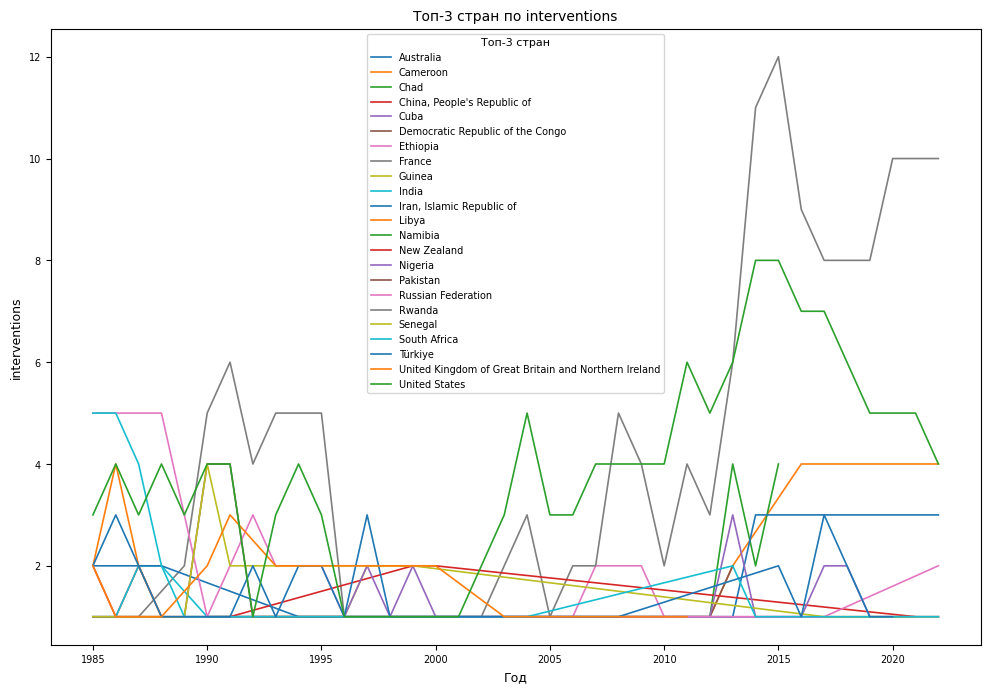

In [1267]:
interventions_df = interventions.load_interventions()
interventions_df, interventions_processed_df = interventions.preprocess_interventions(interventions_df, year_start=1985, neighbourhood_type=None, rolling_window=5)
interventions_df.to_csv("../data/basic_preprocessed/interventions.csv")
interventions_processed_df.to_csv("../data/preprocessed/interventions.csv")

In [18]:
interventions_df = pd.read_csv("../data/basic_preprocessed/interventions.csv").drop('Unnamed: 0', axis=1)
interventions_processed_df = pd.read_csv("../data/preprocessed/interventions.csv").set_index(['ego', 'alter', 'year'])

##### Peacekeeping

#####  Joint military exercises

In [19]:
jme_df = pd.read_csv("../data/basic_preprocessed/jme.csv").drop('Unnamed: 0', axis=1)
jme_processed_df = pd.read_csv("../data/preprocessed/jme.csv").set_index(['ego', 'alter', 'year'])

/tmp/ipykernel_6134/2505486081.py:1: DtypeWarning: Columns (0: series4, 1: airNumC) have mixed types. Specify dtype option on import or set low_memory=False.
  jme_df = pd.read_csv("../data/basic_preprocessed/jme.csv").drop('Unnamed: 0', axis=1)


##### Military deployments

In [11]:
# from https://github.com/EmilStasevski/Military-Deployment/tree/main
# based on IISS Military Balance

INFO:root:Removing UN-related data
INFO:root:Loaded IMDT deployments data
INFO:root:Preprocessing IMDT Depoyment Data
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier TAIWAN, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier Taiwan, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")


GERMANY Germany
Rwanda Rwanda
Lithuania Lithuania
Mozambique Mozambique
Albania Albania
Slovakia Slovakia
German Democratic Republic German Democratic Republic
Congo, Republic of Congo
ETHIOPIA Ethiopia
Cuba Cuba
URUGUAY Uruguay
SAUDI ARABIA Saudi Arabia
Indonesia Indonesia
Guinea Guinea
INDONESIA Indonesia
BELGIUM Belgium
United Arab Emirates United Arab Emirates
Vietnam Viet Nam
Malaysia Malaysia
NEW ZEALAND New Zealand
TANZANIA United Republic of Tanzania
PORTUGAl Portugal
South Africa South Africa
Costa Rica Costa Rica
MALAYSIA Malaysia
KYRGYZSTAN Kyrgyzstan
Chile Chile
Kuwait Kuwait
Korea, Republic of Republic of Korea
TAJIKISTAN Tajikistan
Macedonia Republic of North Macedonia
LITHUANIA Lithuania
Netherlands Netherlands
FIJI Fiji
Philippines Philippines
Mexico Mexico
SERBIA Serbia
Hungary Hungary
Ireland Ireland
Tanzania United Republic of Tanzania
GEORGIA Georgia
CZECH REPUBLIC Czechia
Cyprus Cyprus
Italy Italy
Canada Canada
BULGARIA Bulgaria
KUWAIT Kuwait
Armenia Armenia
United

/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier S. Yemen, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier KOSOVO, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier North Yemen, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier South Yemen, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_t

Rwanda Rwanda
Liberia Liberia
Slovakia Slovakia
S. Yemen None
Guinea Guinea
Panama Panama
Zaire Democratic Republic of the Congo
Vietnam Viet Nam
CAMEROON Cameroon
Venezuela Venezuela (Bolivarian Republic of)
kuwait Kuwait
NEPAL Nepal
KYRGYZSTAN Kyrgyzstan
MALAYSIA Malaysia
Korea, Republic of Republic of Korea
West Germany Germany
Macedonia Republic of North Macedonia
Netherlands Netherlands
Mexico Mexico
YUGOSLAVIA Serbia
Democratic republic of the Congo Democratic Republic of the Congo
Finland Finland
Ivory Coast Côte d'Ivoire
France France
UAE United Arab Emirates
Cameroon Cameroon
Brunei Brunei Darussalam
Uzbekistan Uzbekistan
NETHERLANDS Netherlands
Cote D'Ivoire Côte d'Ivoire
Burkina Faso Burkina Faso
Tunisia Tunisia
Spain Spain
NORWAY Norway
Bangladesh Bangladesh
CANADA Canada
Azerbaijan Azerbaijan
ERITREA Eritrea
JORDAN Jordan
China China, People's Republic of
GABON Gabon
Gambia Gambia
Poland Poland
KOSOVO None
Somalia Somalia
Algeria Algeria
Iran Iran, Islamic Republic of
BURK

DEBUG:root:getting all countries for df
DEBUG:data_handling.gsheet_handler:1. try:
DEBUG:root:reading google table country_data, sheet countryids
DEBUG:urllib3.connectionpool:Resetting dropped connection: www.googleapis.com


Tanzania United Republic of Tanzania
MALTA Malta
CONGO Congo
Armenia Armenia
Nicaragua Nicaragua
Jamaica Jamaica
Mali Mali
Senegal Senegal
Taiwan None
Sierra Leone Sierra Leone
Kyrgyzstan Kyrgyzstan
Trinidad and Tobago Trinidad and Tobago
Switzerland Switzerland
Madagascar Madagascar
AZERBAIJAN Azerbaijan
Comoros Comoros
German Federal Republic Germany
GAMBIA Gambia
GREECE Greece
Norway Norway
BAHRAIN Bahrain
Guinea Bissau Guinea-Bissau
iraq Iraq
Bahrain Bahrain
PORTUGAL Portugal
Equatorial Guinea Equatorial Guinea
Angola Angola
Hong Kong None
CÔTE D'IVOIRE Côte d'Ivoire
Uganda Uganda
Burundi Burundi
Yemen Yemen
Saudi Arabia Saudi Arabia
SUDAN Sudan
ARMENIA Armenia
Portugal Portugal
Us United States
SIERRA LEONE Sierra Leone
TAJikistan Tajikistan
Nigeria Nigeria
BURUNDI Burundi
Bosnia Bosnia and Herzegovina
Serbia Serbia
East Germany German Democratic Republic
Austria Austria
SPAIN Spain
BOSNIA Bosnia and Herzegovina
United Kingdom United Kingdom of Great Britain and Northern Ireland
L

DEBUG:urllib3.connectionpool:https://www.googleapis.com:443 "GET /drive/v3/files?q=mimeType%3D%22application%2Fvnd.google-apps.spreadsheet%22+and+name+%3D+%22country_data%22&pageSize=1000&supportsAllDrives=True&includeItemsFromAllDrives=True&fields=kind%2CnextPageToken%2Cfiles%28id%2Cname%2CcreatedTime%2CmodifiedTime%29 HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:Resetting dropped connection: sheets.googleapis.com
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1-A17WUw0EPdt2PFFJAC0F31w7I-jSCuAbmGwc9JWHnQ?includeGridData=false HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1-A17WUw0EPdt2PFFJAC0F31w7I-jSCuAbmGwc9JWHnQ?includeGridData=false HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1-A17WUw0EPdt2PFFJAC0F31w7I-jSCuAbmGwc9JWHnQ/values/%27countryids%27?valueRenderOption=UNFORMATTED_VALUE&dateTimeRenderOption=FORMATTED_STRING HTTP/1.1

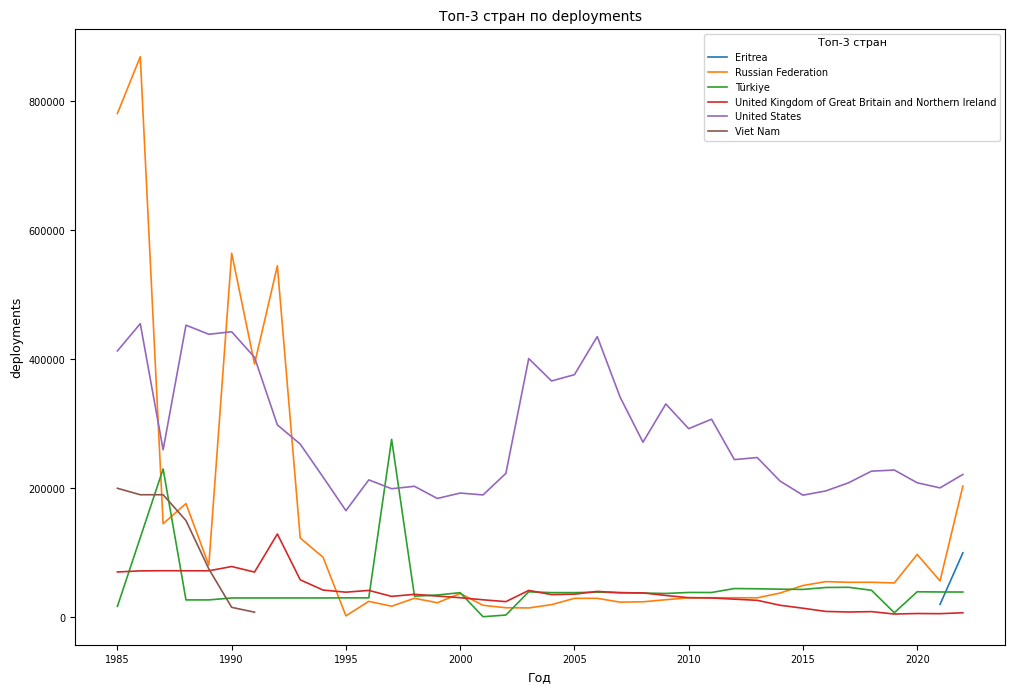

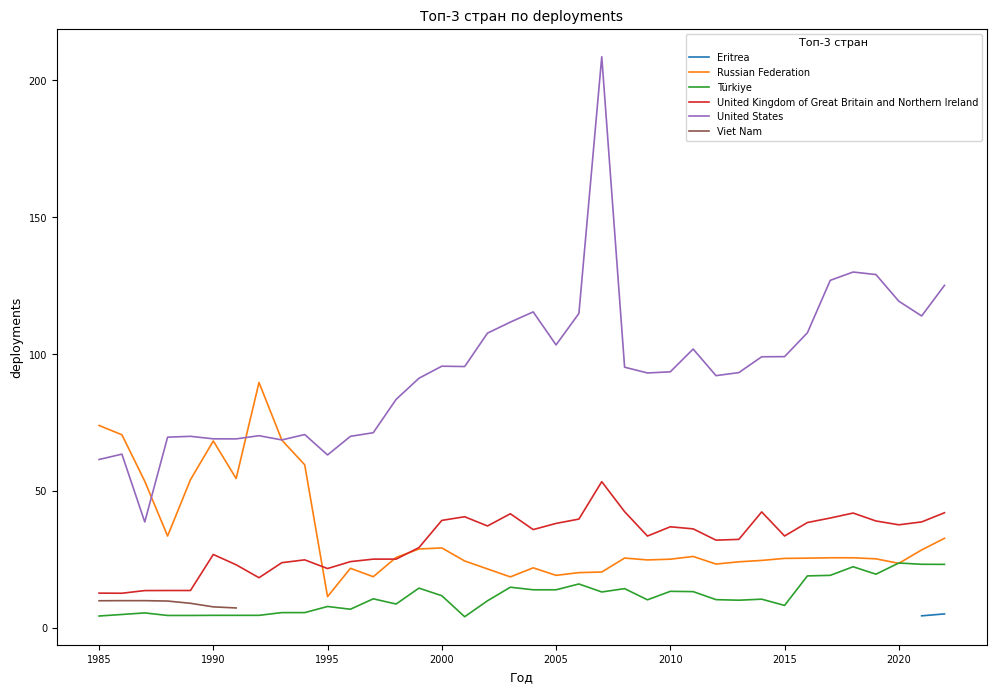

In [1329]:
deployments_df = deployments.load_deployments(filter_un=True)
deployments_df, deployments_processed_df = deployments.preprocess_deployments(deployments_df, year_start=YEAR_START, logarithmic=True)
deployments_df.to_csv("../data/basic_preprocessed/deployments.csv")
deployments_processed_df.to_csv("../data/preprocessed/deployments.csv")

In [21]:
deployments_df = pd.read_csv("../data/basic_preprocessed/deployments.csv").drop('Unnamed: 0', axis=1)
deployments_processed_df = pd.read_csv("../data/preprocessed/deployments.csv").set_index(['ego', 'alter', 'year'])

##### Merging

In [1033]:
d_ = interventions_processed_df.reset_index()
d_['value'] = d_['value'].replace(0, None)
d_ = d_.dropna()
d_=d_.groupby(['ego','year']).sum().reset_index()
d_[d_['ego']=='Sweden']

,ego,year,alter,value
773,Sweden,1990,Saudi Arabia,190.557382
774,Sweden,1991,Saudi Arabia,381.114765
775,Sweden,1992,Saudi Arabia,381.114765
776,Sweden,1993,Saudi Arabia,381.114765
777,Sweden,1994,Saudi Arabia,381.114765
778,Sweden,1995,Saudi Arabia,190.557382


In [1032]:
d_ = sipri_processed_df.reset_index()
d_['value'] = d_['value'].replace(0, None)
d_ = d_.dropna()
d_=d_.groupby(['ego','year']).sum().reset_index()
d_[d_['ego']=='Sweden']

,ego,year,alter,value
1897,Sweden,1985,AustraliaAustriaBahrainBrazilCanadaDenmarkGabo...,969.316086
1898,Sweden,1986,AustraliaAustriaBahrainBrazilCanadaDenmarkGabo...,873.660853
1899,Sweden,1987,AustraliaAustriaBahrainBrazilCanadaDenmarkFinl...,1315.162701
1900,Sweden,1988,AustraliaAustriaBahrainBrazilCanadaDenmarkFinl...,1039.941344
1901,Sweden,1989,AustraliaAustriaBahrainBrazilCanadaDenmarkFinl...,893.516329
1902,Sweden,1990,AustraliaAustriaCanadaDenmarkFinlandIndiaMalay...,702.773732
1903,Sweden,1991,AustraliaAustriaDenmarkFinlandMalaysiaNew Zeal...,614.839116
1904,Sweden,1992,AustraliaAustriaDenmarkFinlandMalaysiaNew Zeal...,184.493396
1905,Sweden,1993,AustraliaAustriaEstoniaFinlandJapanLatviaLithu...,146.244571
1906,Sweden,1994,AustraliaBrazilEstoniaFinlandIndonesiaJapanLat...,142.578638


INFO:root:saving figure
INFO:root:saving figure
INFO:root:saving figure


{'interventions':                          ego          value
0                   Ethiopia   24089.629096
1                     Uganda   24994.776663
2                   Cameroon   27630.820453
3                    Nigeria   32394.755014
4  Iran, Islamic Republic of   35253.115750
5               South Africa   36841.093937
6                    Türkiye   36999.891756
7         Russian Federation   48592.132521
8                     France  130436.528276
9              United States  133707.763342, 'sipri':                                                  ego          value
0                                              Spain   22042.693017
1                                             Israel   22980.873509
2                                        Netherlands   25698.081049
3                                              Italy   33106.021617
4                        China, People's Republic of   65317.565953
5  United Kingdom of Great Britain and Northern I...   75657.805301
6           

INFO:root:saving figure


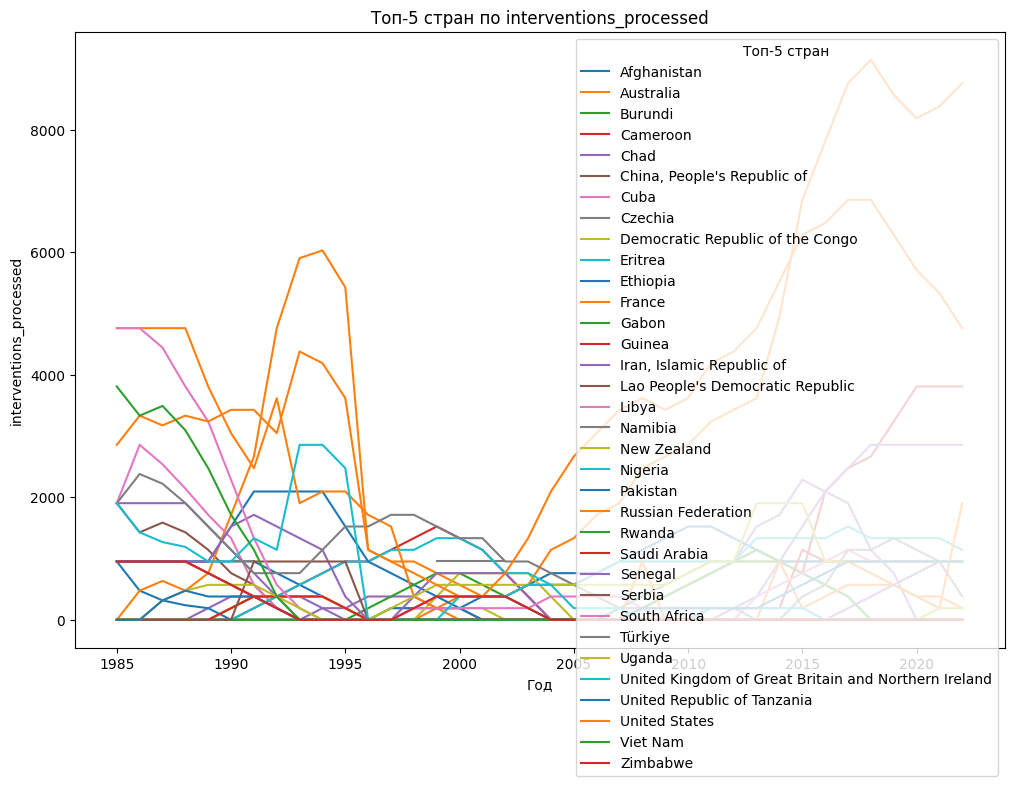

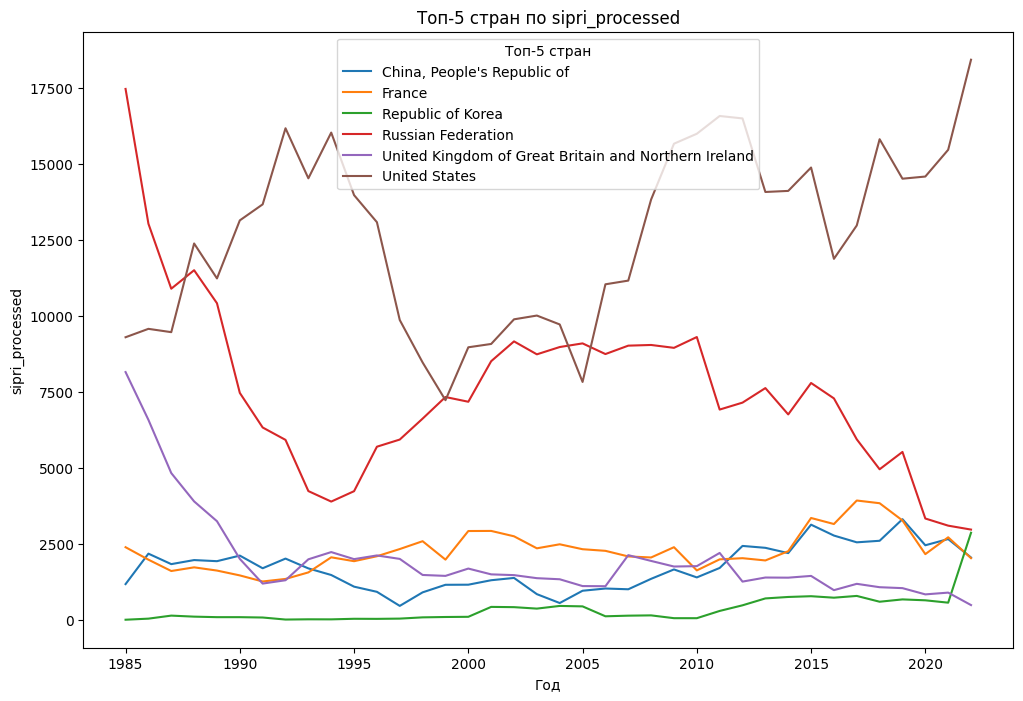

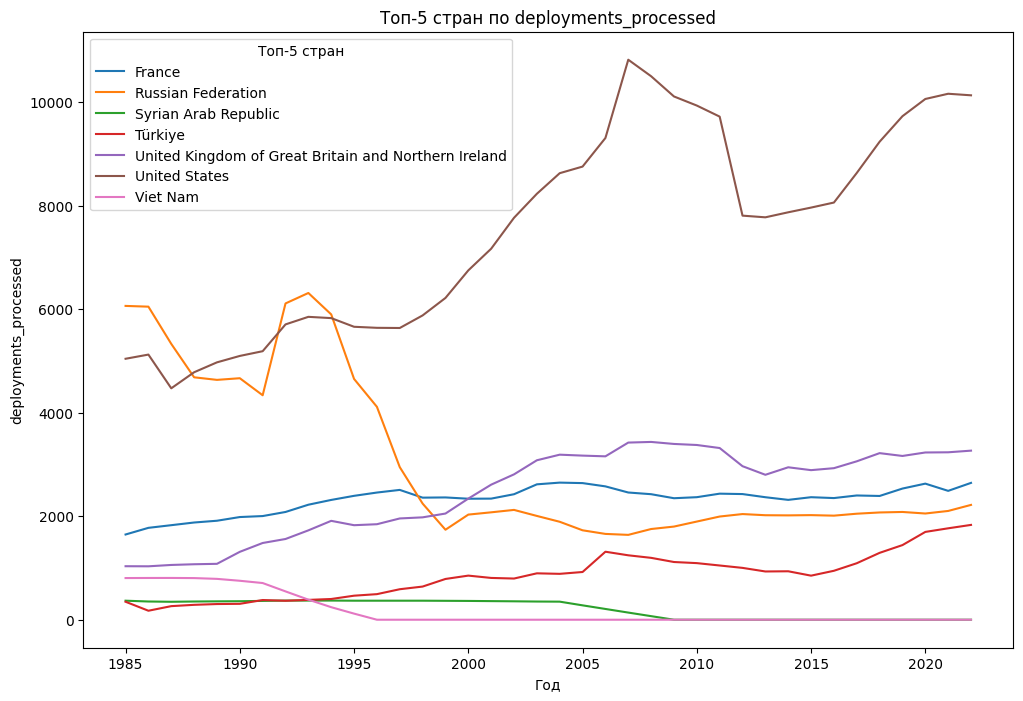

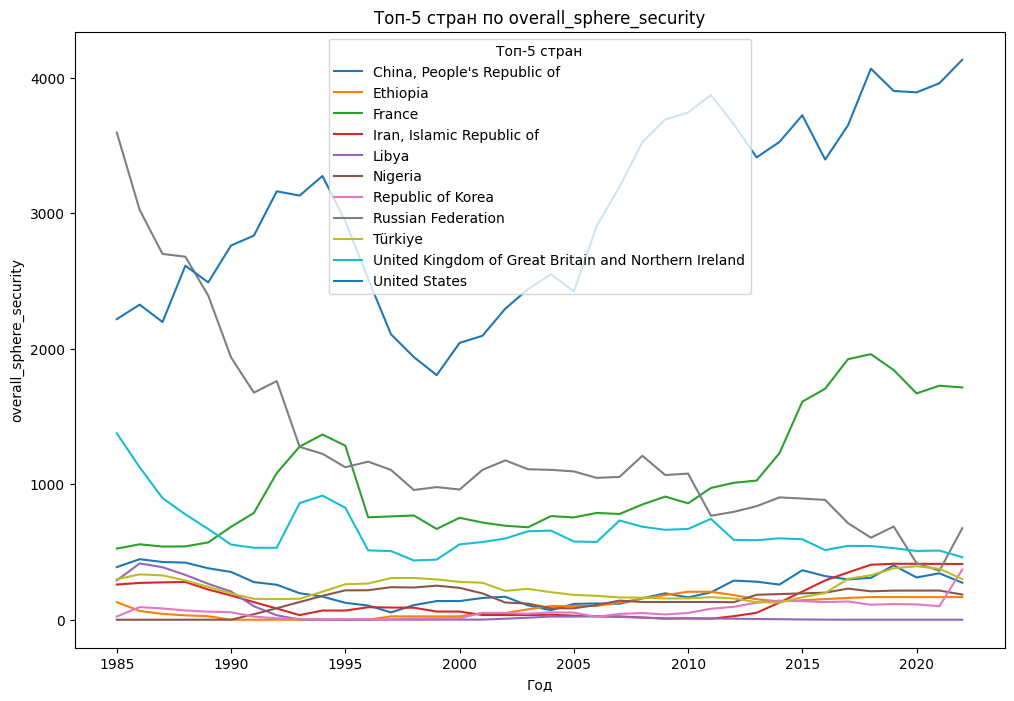

In [22]:
security_dfs = {
    'interventions':interventions_processed_df,
    'sipri':sipri_processed_df,
    'deployments':deployments_processed_df,          
    #'jme':jme_processed_df
}
security_triple = merge_sphere(security_dfs, SECURITY_WEIGHTS, test=True, label='security')

### Economy

##### FDI (UNCTAD + Investment_map + IMF)

In [23]:
fdi_df = pd.read_csv("../data/basic_preprocessed/fdi.csv", index_col = 'Unnamed: 0')
fdi_processed_df = pd.read_csv("../data/preprocessed/fdi.csv", index_col = 'index').set_index(['ego', 'alter', 'year'])
#fdi_df_historic_extended = pd.read_csv("../data/preprocessed/fdi_historic.csv").set_index(['ego', 'year'])

/tmp/ipykernel_6134/1110134941.py:1: DtypeWarning: Columns (0: value_imf, 1: value_imf_inmirror) have mixed types. Specify dtype option on import or set low_memory=False.
  fdi_df = pd.read_csv("../data/basic_preprocessed/fdi.csv", index_col = 'Unnamed: 0')


#### Trade

INFO:root:reading 1985_1988_TradeData_3_18_2025_7_35_8.csv
INFO:root:reading 1989_1994_TradeData_3_18_2025_7_35_8.csv
INFO:root:reading 1995_2000.csv
INFO:root:reading 2001_2004.csv
INFO:root:reading 2005_2008.csv
INFO:root:reading 2009_2012.csv
INFO:root:reading 2013_2016.csv
INFO:root:reading 2017_2020.csv
INFO:root:reading 2021_2022.csv
INFO:root:reading 1985_1994_USSR_RUssia_mirror.csv
INFO:root:reading 2001_2012_SaudiArabia_Venezuela_Libya_mirror.csv
INFO:root:reading 2013_2022_SaudiArabia_Venezuela_Libya_mirror.csv
INFO:root:reading 1989_1994_Andorra_mirror.csv
INFO:root:reading 1985_1988_Andorra_mirror.csv
INFO:root:Removing 47 rows from <StringArray>
['VEN', 'LBY', 'SAU', 'S19', 'ISR', 'PAK', 'CHN']
Length: 7, dtype: str, years [2006 2008 2005 2004 2013 2012 2001 2011 2014 2002 2007 2010 2003 2021
 2022 2019 2018 2009 2020 2015 2017 2016 1999 1995 1996 1997 1998 2000
 1988 1986 1992 1991 1989 1987]
INFO:root:Preprocessing trade data
/home/alex-server/Sync/Работа/Code/phd_thesis

MRT Mauritania
LSO Lesotho
NIC Nicaragua
IRQ Iraq
S19 None
SUR Suriname
MLI Mali
NCL None
ZA1 None
AGO Angola
LAO Lao People's Democratic Republic
GIN Guinea
SRB Serbia
COD Democratic Republic of the Congo
TJK Tajikistan
CPV Cabo Verde
KIR Kiribati
EST Estonia
BTN Bhutan
MTQ None
AFG Afghanistan
MYT None
GEO Georgia
SCG Serbia
GRC Greece
ARM Armenia
PNG Papua New Guinea
BGR Bulgaria
LVA Latvia
MNG Mongolia
BEL Belgium
BMU None
ZMB Zambia
CRI Costa Rica
EGY Egypt
CUB Cuba
PRY Paraguay
MDG Madagascar
YMD None
ISR Israel
ZAF South Africa
KWT Kuwait
AUT Austria
CHE Switzerland
ALB Albania
NIU None
QAT Qatar
KOR Republic of Korea
BOL Bolivia (Plurinational State of)
LCA Saint Lucia
WSM Samoa
PAK Pakistan
SLB Solomon Islands
MAR Morocco
MNE Montenegro
GNB Guinea-Bissau
TZA United Republic of Tanzania
POL Poland
COL Colombia
DDR None
AUS Australia
SGP Singapore
FIN Finland
PYF None
GAB Gabon
YEM Yemen
BHR Bahrain
IND India
SYR Syrian Arab Republic
GUY Guyana
LBN Lebanon
CZE Czechia
VNM Viet N

/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier S19, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier NCL, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier ZA1, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier A79, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/country

LSO Lesotho
MRT Mauritania
NIC Nicaragua
IRQ Iraq
S19 None
SUR Suriname
MLI Mali
NCL None
ZA1 None
A79 None
AGO Angola
O19 None
LAO Lao People's Democratic Republic
GIN Guinea
COD Democratic Republic of the Congo
SRB Serbia
TJK Tajikistan
ATA None
CPV Cabo Verde
BLM None
EST Estonia
KIR Kiribati
BTN Bhutan
MTQ None
AFG Afghanistan
MYT None
GEO Georgia
SCG Serbia
GRC Greece
ARM Armenia
PNG Papua New Guinea
BGR Bulgaria
LVA Latvia
MNG Mongolia
SOM Somalia
BEL Belgium
BMU None
NFK None
ZMB Zambia
CRI Costa Rica
EGY Egypt
CUB Cuba
PRY Paraguay
MDG Madagascar
R20 None
FLK None
YMD None
ISR Israel
PCN None
ZAF South Africa
KWT Kuwait
AUT Austria
CHE Switzerland
ALB Albania
NIU None
NRU Nauru
QAT Qatar
KOR Republic of Korea
LCA Saint Lucia
BOL Bolivia (Plurinational State of)
WSM Samoa
PAK Pakistan
SLB Solomon Islands
MAR Morocco
MNE Montenegro
GNB Guinea-Bissau
ASM None
TZA United Republic of Tanzania
POL Poland
COL Colombia
DDR None
TKL None
E19 None
AUS Australia
SGP Singapore
FIN Finland


DEBUG:root:getting all countries for df
DEBUG:data_handling.gsheet_handler:1. try:
DEBUG:root:reading google table country_data, sheet countryids
DEBUG:urllib3.connectionpool:Resetting dropped connection: www.googleapis.com
DEBUG:urllib3.connectionpool:https://www.googleapis.com:443 "GET /drive/v3/files?q=mimeType%3D%22application%2Fvnd.google-apps.spreadsheet%22+and+name+%3D+%22country_data%22&pageSize=1000&supportsAllDrives=True&includeItemsFromAllDrives=True&fields=kind%2CnextPageToken%2Cfiles%28id%2Cname%2CcreatedTime%2CmodifiedTime%29 HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:Resetting dropped connection: sheets.googleapis.com
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1-A17WUw0EPdt2PFFJAC0F31w7I-jSCuAbmGwc9JWHnQ?includeGridData=false HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1-A17WUw0EPdt2PFFJAC0F31w7I-jSCuAbmGwc9JWHnQ?includeGridData=false HTTP/1.1" 200 None
DEBUG:urllib

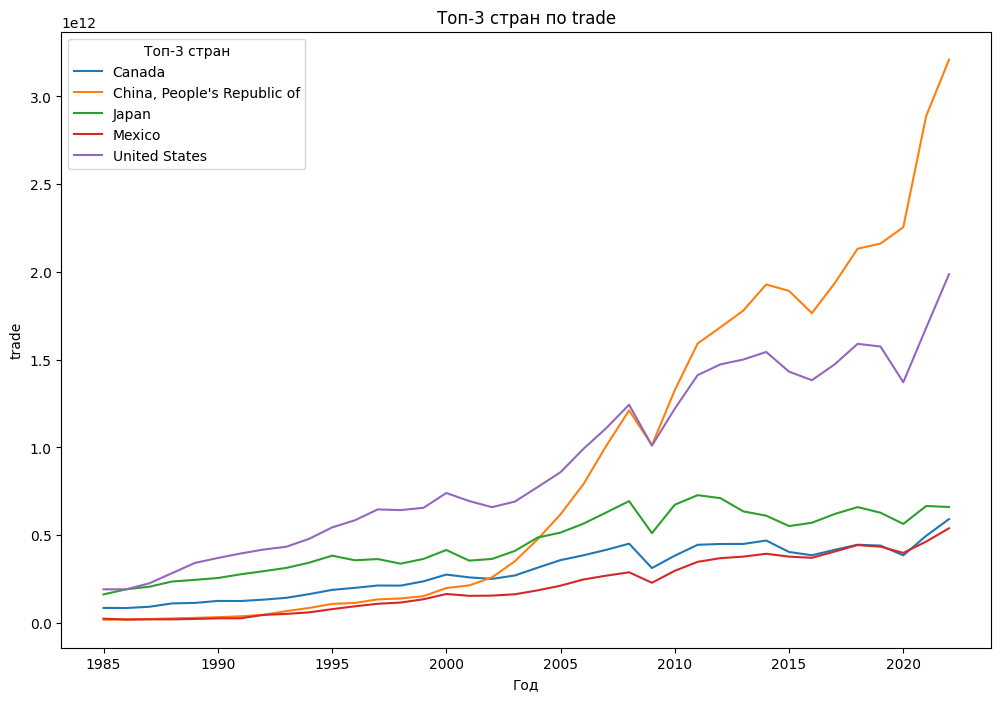

In [858]:
trade_df = trade.load_trade()
trade_df, trade_processed_df = trade.preprocess_trade(trade_df, year_start=YEAR_START, rolling_window=5)
trade_df.to_csv("../data/basic_preprocessed/trade.csv")
trade_processed_df.to_csv("../data/preprocessed/trade.csv")

In [24]:
trade_df = pd.read_csv("../data/basic_preprocessed/trade.csv")
trade_processed_df = pd.read_csv("../data/preprocessed/trade.csv").set_index(['ego', 'alter', 'year'])

#### Hi-tech trade

INFO:root:reading 2005.csv


['2005.csv', '2019.csv', '1996.csv', '2021.csv', '1989.csv', '2006.csv', '2022.csv', '2000.csv', '1990.csv', '2002.csv', '1992.csv', '2020.csv', '1997.csv', '2004.csv', '1993.csv', '2001.csv', '2018.csv', '1991.csv', '1998.csv', '1999.csv', '1995.csv', '2003.csv', '1994.csv', '2007.csv', '2008.csv', '2009.csv', '2017.csv', '2010.csv', '2011.csv', '2015.csv', '2016.csv', '2012.csv', '2014.csv', '2013.csv', '1988.csv', '1987.csv', '1986.csv', '1985.csv', '1985_1995_USSR_RUssia_mirror.csv', '2013_2024_SaudiArabia_Venezuela_Libya_mirror.csv', '2001_2012_SaudiArabia_Venezuela_Libya_mirror.csv']


INFO:root:reading 2019.csv
INFO:root:reading 1996.csv
INFO:root:reading 2021.csv
INFO:root:reading 1989.csv
INFO:root:reading 2006.csv
INFO:root:reading 2022.csv
INFO:root:reading 2000.csv
INFO:root:reading 1990.csv
INFO:root:reading 2002.csv
INFO:root:reading 1992.csv
INFO:root:reading 2020.csv
INFO:root:reading 1997.csv
INFO:root:reading 2004.csv
INFO:root:reading 1993.csv
INFO:root:reading 2001.csv
INFO:root:reading 2018.csv
INFO:root:reading 1991.csv
INFO:root:reading 1998.csv
/home/alex-server/Sync/Работа/Code/phd_thesis/code/data_handling/hitech.py:20: DtypeWarning: Columns (0: qtyUnitAbbr) have mixed types. Specify dtype option on import or set low_memory=False.
  # df_in for exceptions and df_out for main values
INFO:root:reading 1999.csv
INFO:root:reading 1995.csv
INFO:root:reading 2003.csv
INFO:root:reading 1994.csv
INFO:root:reading 2007.csv
/home/alex-server/Sync/Работа/Code/phd_thesis/code/data_handling/hitech.py:20: DtypeWarning: Columns (0: altQtyUnitAbbr) have mixed typ

MRT Mauritania
LSO Lesotho
NIC Nicaragua
IRQ Iraq
S19 None
SUR Suriname
MLI Mali
NCL None
ZA1 None
A79 None
AGO Angola
O19 None
LAO Lao People's Democratic Republic
GIN Guinea
COD Democratic Republic of the Congo
CPV Cabo Verde
KIR Kiribati
TJK Tajikistan
ATA None
SRB Serbia
EST Estonia
BLM None
BTN Bhutan
MTQ None
AFG Afghanistan
MYT None
SCG Serbia
GEO Georgia
GRC Greece
ARM Armenia
PNG Papua New Guinea
BGR Bulgaria
LVA Latvia
SOM Somalia
MNG Mongolia
BEL Belgium
BMU None
NFK None
ZMB Zambia
CRI Costa Rica
EGY Egypt
CUB Cuba
PRY Paraguay
MDG Madagascar
FLK None
YMD None
ISR Israel
PCN None
ZAF South Africa
KWT Kuwait
AUT Austria
CHE Switzerland
NRU Nauru
ALB Albania
NIU None
QAT Qatar
BOL Bolivia (Plurinational State of)
KOR Republic of Korea
WSM Samoa
LCA Saint Lucia
PAK Pakistan
SLB Solomon Islands
MAR Morocco
MNE Montenegro
GNB Guinea-Bissau
ASM None
TZA United Republic of Tanzania
POL Poland
COL Colombia
DDR None
TKL None
E19 None
AUS Australia
FIN Finland
SGP Singapore
NTZ None


/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier S19, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier NCL, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier ZA1, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier MTQ, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/country

MRT Mauritania
LSO Lesotho
NIC Nicaragua
S19 None
SUR Suriname
MLI Mali
NCL None
ZA1 None
AGO Angola
LAO Lao People's Democratic Republic
GIN Guinea
SRB Serbia
CPV Cabo Verde
TJK Tajikistan
KIR Kiribati
COD Democratic Republic of the Congo
EST Estonia
BTN Bhutan
MTQ None
AFG Afghanistan
MYT None
SCG Serbia
GEO Georgia
GRC Greece
ARM Armenia
PNG Papua New Guinea
BGR Bulgaria
LVA Latvia
MNG Mongolia
BEL Belgium
BMU None
ZMB Zambia
CRI Costa Rica
EGY Egypt
CUB Cuba
PRY Paraguay
MDG Madagascar
ISR Israel
ZAF South Africa
KWT Kuwait
AUT Austria
CHE Switzerland
ALB Albania
QAT Qatar
BOL Bolivia (Plurinational State of)
KOR Republic of Korea
LCA Saint Lucia
WSM Samoa
PAK Pakistan
SLB Solomon Islands
MAR Morocco
MNE Montenegro
GNB Guinea-Bissau
TZA United Republic of Tanzania
POL Poland
COL Colombia
AUS Australia
FIN Finland
SGP Singapore
PYF None
GAB Gabon
YEM Yemen
BHR Bahrain
IND India
SYR Syrian Arab Republic
GUY Guyana
LBN Lebanon
CZE Czechia
HTI Haiti
VNM Viet Nam
ISL Iceland
NAM Namibia

DEBUG:root:getting all countries for df
DEBUG:data_handling.gsheet_handler:1. try:
DEBUG:root:reading google table country_data, sheet countryids
DEBUG:urllib3.connectionpool:Resetting dropped connection: oauth2.googleapis.com
DEBUG:urllib3.connectionpool:https://oauth2.googleapis.com:443 "POST /token HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:Resetting dropped connection: www.googleapis.com
DEBUG:urllib3.connectionpool:https://www.googleapis.com:443 "GET /drive/v3/files?q=mimeType%3D%22application%2Fvnd.google-apps.spreadsheet%22+and+name+%3D+%22country_data%22&pageSize=1000&supportsAllDrives=True&includeItemsFromAllDrives=True&fields=kind%2CnextPageToken%2Cfiles%28id%2Cname%2CcreatedTime%2CmodifiedTime%29 HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:Resetting dropped connection: sheets.googleapis.com
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1-A17WUw0EPdt2PFFJAC0F31w7I-jSCuAbmGwc9JWHnQ?includeGridData=false HTTP/1.1" 200 None
DEBUG:u

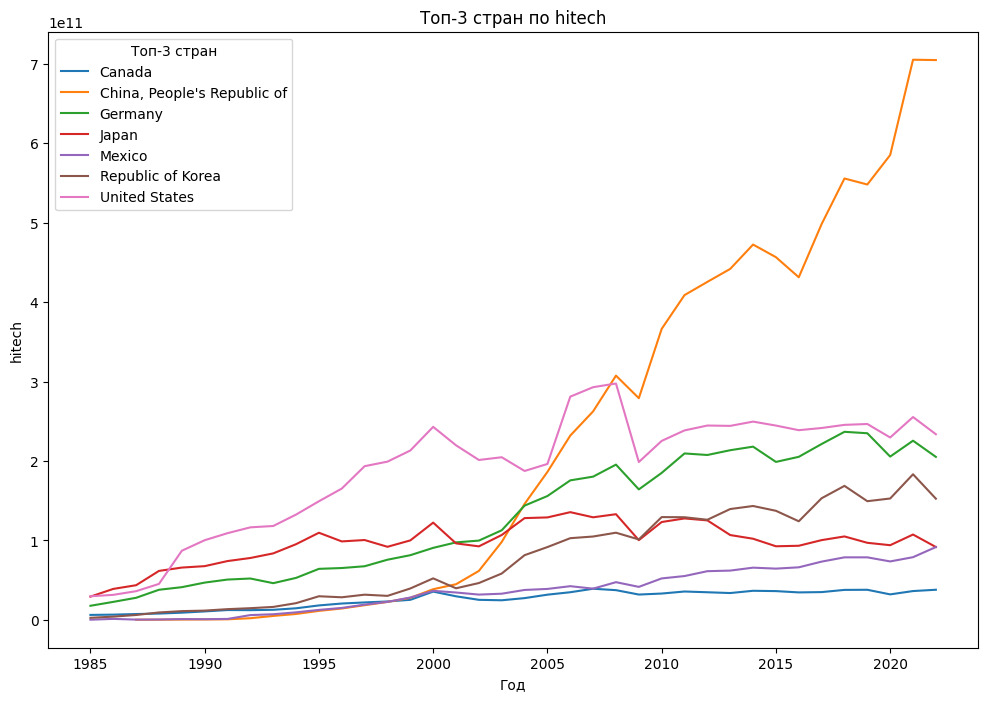

In [855]:
hitech_df = hitech.load_hitech()
hitech_df, hitech_processed_df = hitech.preprocess_hitech(hitech_df, year_start=YEAR_START, rolling_window=5)
hitech_df.to_csv("../data/basic_preprocessed/hitech.csv")
hitech_processed_df.to_csv("../data/preprocessed/hitech.csv")

In [25]:
hitech_df = pd.read_csv("../data/basic_preprocessed/hitech.csv")
hitech_processed_df = pd.read_csv("../data/preprocessed/hitech.csv").set_index(['ego', 'alter', 'year'])

/tmp/ipykernel_6134/2705072775.py:1: DtypeWarning: Columns (0: altQtyUnitAbbr) have mixed types. Specify dtype option on import or set low_memory=False.
  hitech_df = pd.read_csv("../data/basic_preprocessed/hitech.csv")


INFO:root:Сканируем папку: /home/alex-server/Sync/Работа/Code/phd_thesis/data/preprocessed/subsystem_level
INFO:root:Содержимое папки (4 элементов):
INFO:root:  - df_economy_2022.csv
INFO:root:  - df_security_2022.csv
INFO:root:  - df_human_2022.csv
INFO:root:  - .ipynb_checkpoints
INFO:root:Добавлена категория: 'economy' из файла df_economy_2022.csv
INFO:root:Добавлена категория: 'security' из файла df_security_2022.csv
INFO:root:Добавлена категория: 'human' из файла df_human_2022.csv
INFO:root:Найдено уникальных категорий: 3
INFO:root:Итоговый список категорий: ['economy', 'human', 'security']
INFO:root:reading subsystems ['economy', 'human', 'security']


{'economy': {'networks': {1992: <networkx.classes.digraph.DiGraph at 0x7f08ce3a87d0>,
   1993: <networkx.classes.digraph.DiGraph at 0x7f08cdd08cd0>,
   1994: <networkx.classes.digraph.DiGraph at 0x7f08cd8dadd0>,
   1995: <networkx.classes.digraph.DiGraph at 0x7f08cd24fed0>,
   1996: <networkx.classes.digraph.DiGraph at 0x7f08ccc24dd0>,
   1997: <networkx.classes.digraph.DiGraph at 0x7f08cc620810>,
   1998: <networkx.classes.digraph.DiGraph at 0x7f0905310650>,
   1999: <networkx.classes.digraph.DiGraph at 0x7f08cba99f90>,
   2000: <networkx.classes.digraph.DiGraph at 0x7f08cb3330d0>,
   2001: <networkx.classes.digraph.DiGraph at 0x7f08cac473d0>,
   2002: <networkx.classes.digraph.DiGraph at 0x7f08ca5a51d0>,
   2003: <networkx.classes.digraph.DiGraph at 0x7f08c9d2b250>,
   2004: <networkx.classes.digraph.DiGraph at 0x7f08c96f4350>,
   2005: <networkx.classes.digraph.DiGraph at 0x7f08c8ef51d0>,
   2006: <networkx.classes.digraph.DiGraph at 0x7f08c853a810>,
   2007: <networkx.classes.digra

#### Energy trade

In [26]:
energy_df = pd.read_csv("../data/basic_preprocessed/energy.csv")
energy_processed_df = pd.read_csv("../data/preprocessed/energy.csv").set_index(['ego', 'alter', 'year'])

#### Merging

INFO:root:saving figure
INFO:root:saving figure
INFO:root:saving figure
INFO:root:saving figure


{'fdi':                                                  ego          value
0                                              Spain   19880.907746
1                                          Singapore   26255.662359
2                                              Italy   27617.136192
3                        China, People's Republic of   31289.572609
4                                         Luxembourg   35710.130146
5                                            Germany   36733.935259
6                                             France   95246.130337
7  United Kingdom of Great Britain and Northern I...  101028.914978
8                                        Netherlands  111012.228206
9                                      United States  438793.442729, 'trade':                                                  ego          value
0                                  Republic of Korea   38928.932512
1                                             Canada   44622.624473
2                             

INFO:root:saving figure


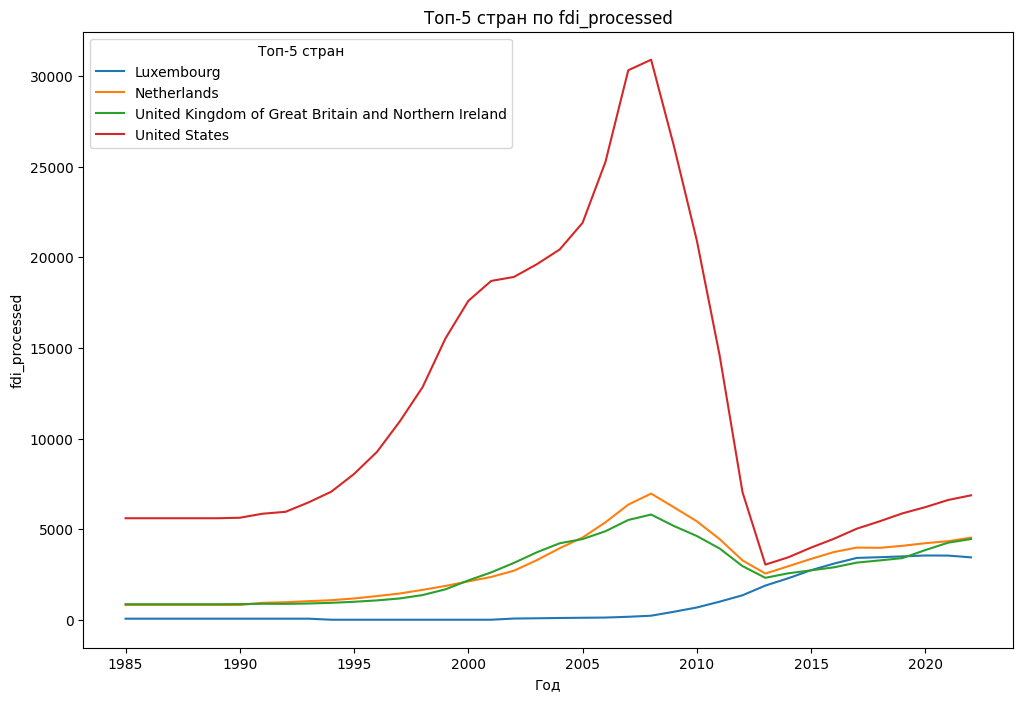

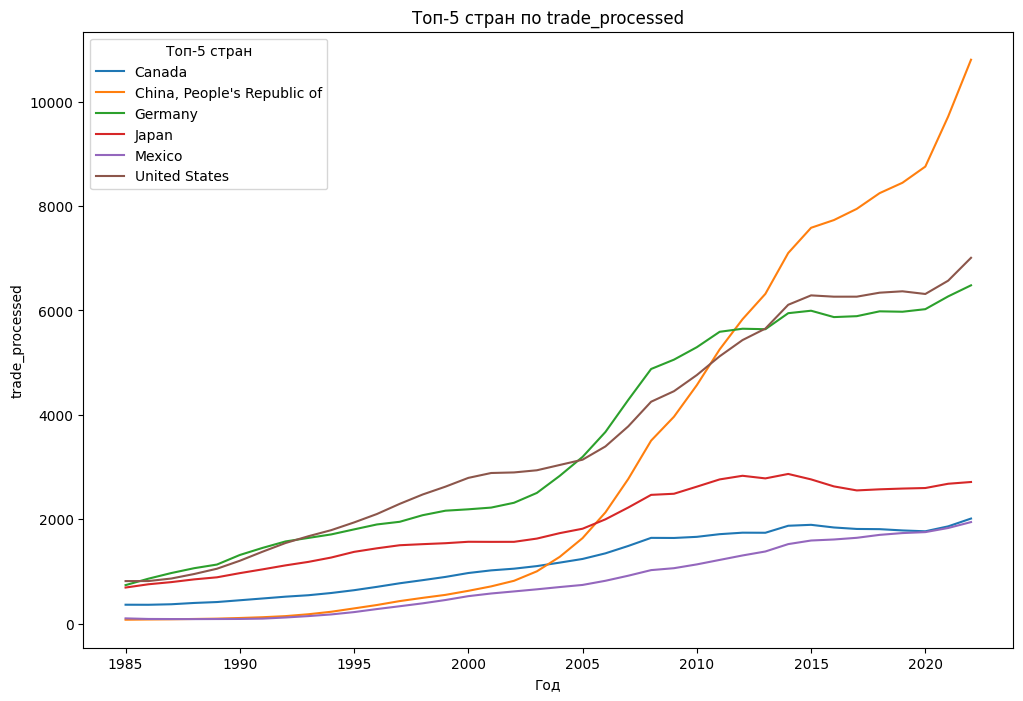

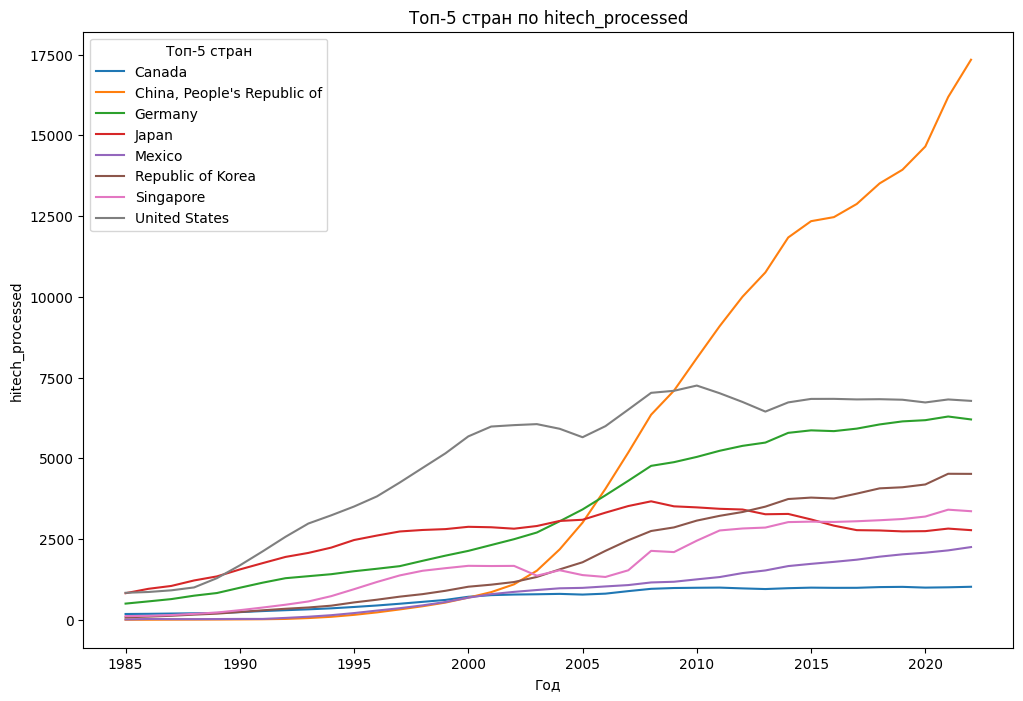

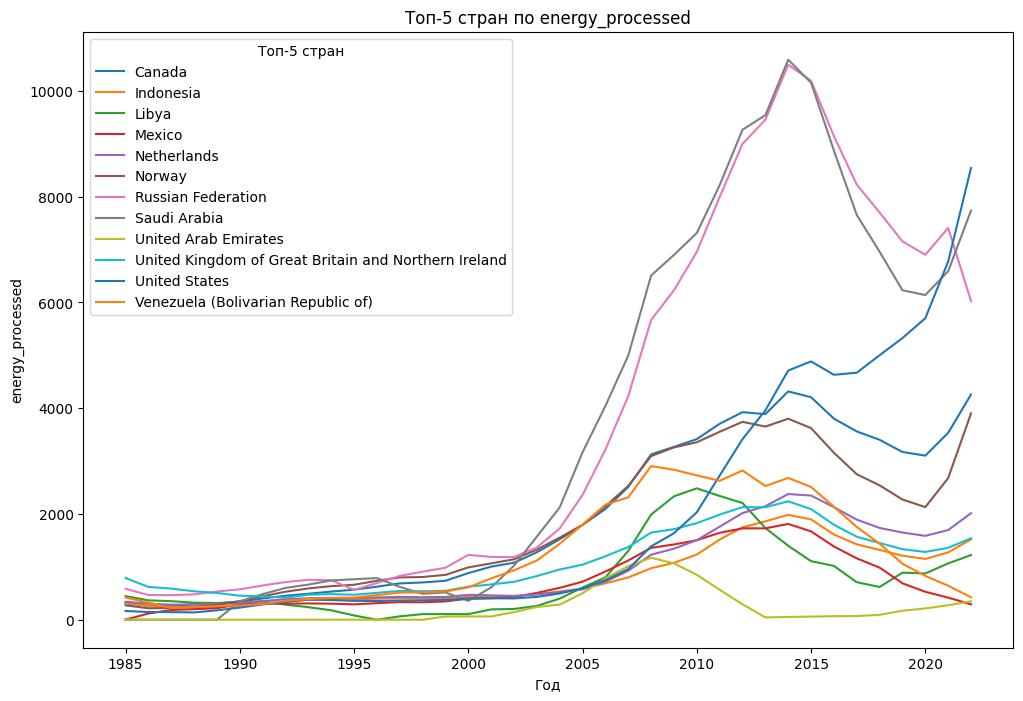

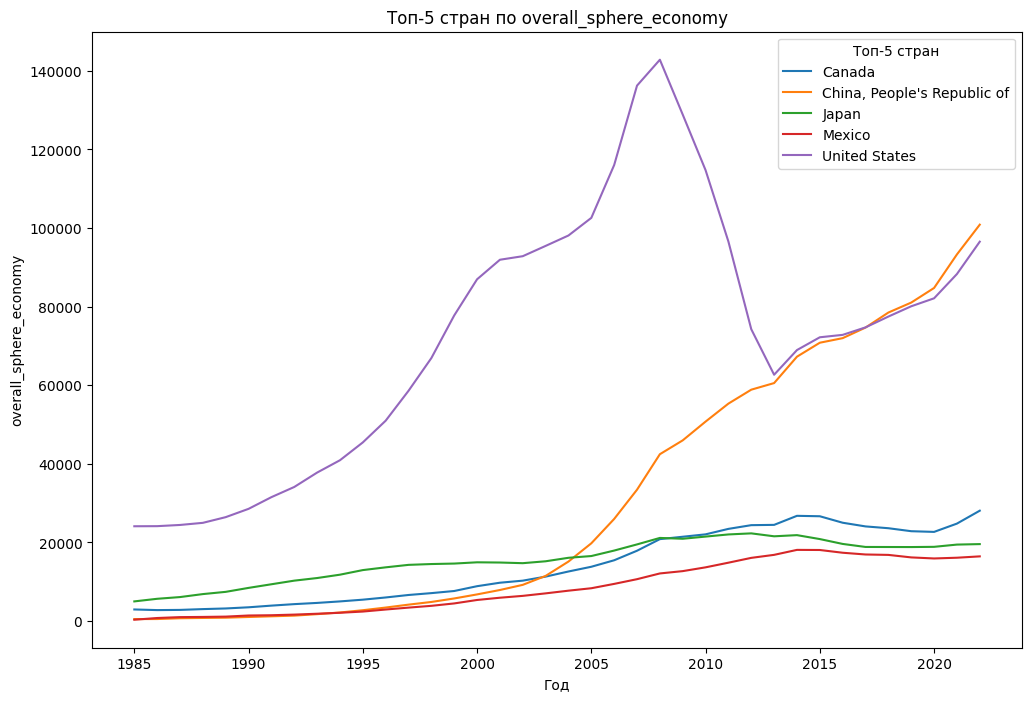

In [27]:
economy_dfs = {
    'fdi':fdi_processed_df,
    'trade':trade_processed_df,
    'hitech':hitech_processed_df,
    'energy':energy_processed_df
}
economy_triple = merge_sphere(economy_dfs, ECONOMY_WEIGHTS, test=True, label='economy')

In [ ]:
d=fdi_processed_df.reset_index().groupby(['year', 'ego']).sum().reset_index()
d[d['ego']=='Russian Federation']

### Humanitarian Data

#### Refugee

In [ ]:
# по хорошему бы еще данные из unknown и stateless экстраполировать
# logarithmic=True приводит к тому, что страны с небольшим количеством беженцев из большого числа стран получают высокие значения

INFO:root:Preprocessing refugee data
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier Western Sahara, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier Bermuda, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier New Caledonia, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier Serbia and Kosovo: S/RES/1244 (1999), replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, repl

Peru Peru
Rwanda Rwanda
Congo Congo
Mozambique Mozambique
Albania Albania
Liberia Liberia
Lithuania Lithuania
Slovakia Slovakia
Dem. People's Rep. of Korea Democratic People's Republic of Korea
Cuba Cuba
Saint Lucia Saint Lucia
Indonesia Indonesia
Guinea Guinea
Russian Federation Russian Federation
Panama Panama
United Arab Emirates United Arab Emirates
Dominica Dominica
Andorra Andorra
Cote d'Ivoire Côte d'Ivoire
Solomon Islands Solomon Islands
Sri Lanka Sri Lanka
Guatemala Guatemala
South Africa South Africa
Malaysia Malaysia
Costa Rica Costa Rica
Belize Belize
Iraq Iraq
Chile Chile
Kuwait Kuwait
Western Sahara None
Bermuda None
Sao Tome and Principe Sao Tome and Principe
Mexico Mexico
Philippines Philippines
Dominican Rep. Dominican Republic
Hungary Hungary
Ireland Ireland
Bhutan Bhutan
Syrian Arab Rep. Syrian Arab Republic
Cyprus Cyprus
Italy Italy
Canada Canada
Armenia Armenia
United States of America United States
Nicaragua Nicaragua
Croatia Croatia
Finland Finland
Zambia Zambia


/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier Sint Maarten (Dutch part), replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier Serbia and Kosovo: S/RES/1244 (1999), replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier Cayman Islands, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier China, Hong Kong SAR, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {

Peru Peru
Rwanda Rwanda
Mozambique Mozambique
Congo Congo
Liberia Liberia
Albania Albania
Slovakia Slovakia
Lithuania Lithuania
Dem. People's Rep. of Korea Democratic People's Republic of Korea
Cuba Cuba
Saint Lucia Saint Lucia
Indonesia Indonesia
Guinea Guinea
Russian Federation Russian Federation
Panama Panama
United Arab Emirates United Arab Emirates
Cote d'Ivoire Côte d'Ivoire
Solomon Islands Solomon Islands
Sri Lanka Sri Lanka
Guatemala Guatemala
Malaysia Malaysia
South Africa South Africa
Belize Belize
Costa Rica Costa Rica
Iraq Iraq
Chile Chile
Kuwait Kuwait
Sint Maarten (Dutch part) None
Mexico Mexico
Dominican Rep. Dominican Republic
Philippines Philippines
Hungary Hungary
Ireland Ireland
Syrian Arab Rep. Syrian Arab Republic
Cyprus Cyprus
Italy Italy
Canada Canada
Armenia Armenia
United States of America United States
Nicaragua Nicaragua
Croatia Croatia
Finland Finland
Zambia Zambia
Jamaica Jamaica
France France
Bahamas Bahamas
Brazil Brazil
Mali Mali
United Kingdom of Great 

DEBUG:root:getting all countries for df
DEBUG:data_handling.gsheet_handler:1. try:
DEBUG:root:reading google table country_data, sheet countryids
DEBUG:urllib3.connectionpool:Resetting dropped connection: oauth2.googleapis.com


Tajikistan Tajikistan
Uruguay Uruguay
Curacao  None
Australia Australia
New Zealand New Zealand
Timor-Leste Timor-Leste
Lesotho Lesotho


DEBUG:urllib3.connectionpool:https://oauth2.googleapis.com:443 "POST /token HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:Resetting dropped connection: www.googleapis.com
DEBUG:urllib3.connectionpool:https://www.googleapis.com:443 "GET /drive/v3/files?q=mimeType%3D%22application%2Fvnd.google-apps.spreadsheet%22+and+name+%3D+%22country_data%22&pageSize=1000&supportsAllDrives=True&includeItemsFromAllDrives=True&fields=kind%2CnextPageToken%2Cfiles%28id%2Cname%2CcreatedTime%2CmodifiedTime%29 HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:Resetting dropped connection: sheets.googleapis.com
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1-A17WUw0EPdt2PFFJAC0F31w7I-jSCuAbmGwc9JWHnQ?includeGridData=false HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1-A17WUw0EPdt2PFFJAC0F31w7I-jSCuAbmGwc9JWHnQ?includeGridData=false HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 

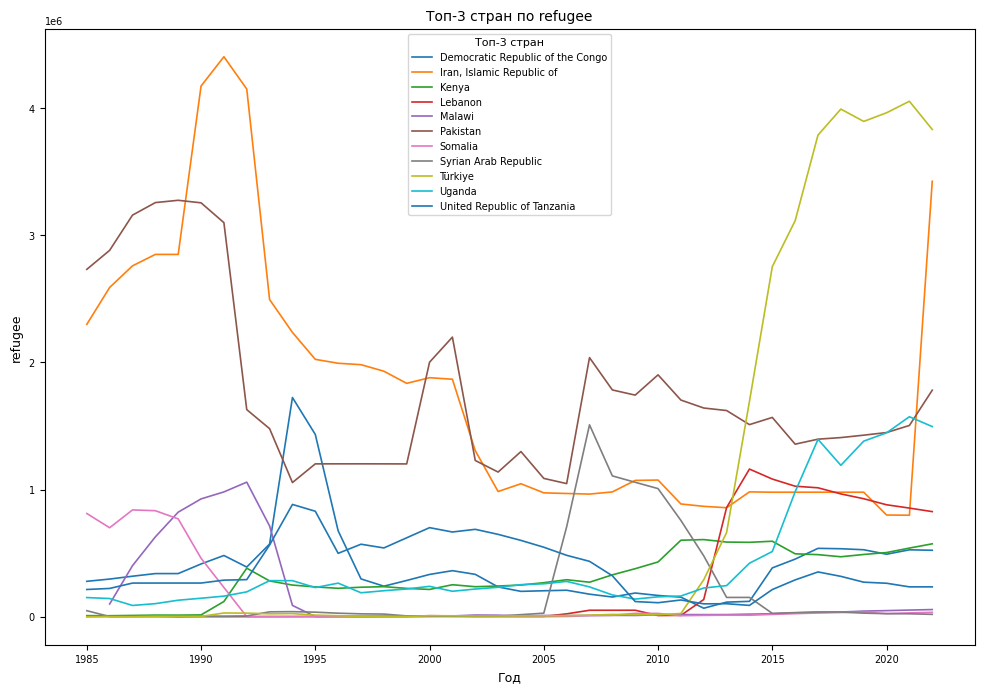

In [1305]:
refugee_df = refugee.load_refugee()
refugee_df,refugee_processed_df = refugee.preprocess_refugee(refugee_df, year_start=YEAR_START, rolling_window=1, logarithmic=False)
refugee_df.to_csv("../data/basic_preprocessed/refugee_nolog.csv")
refugee_processed_df.to_csv("../data/preprocessed/refugee_nolog.csv")

In [34]:
refugee_df = pd.read_csv("../data/basic_preprocessed/refugee_nolog.csv")
refugee_processed_df = pd.read_csv("../data/preprocessed/refugee_nolog.csv").set_index(['ego', 'alter', 'year'])

#### Migrant

INFO:root:Preprocessing migrant data
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier 1836, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier 935, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier 910, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier 796, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Раб

242 Fiji
1836 None
48 Bahrain
352 Iceland
740 Suriname
858 Uruguay
935 None
608 Philippines
170 Colombia
910 None
702 Singapore
796 None
706 Somalia
666 None
800 Uganda
931 None
12 Algeria
400 Jordan
1831 None
300 Greece
927 None
404 Kenya
24 Angola
705 Slovenia
925 None
478 Mauritania
840 United States
1829 None
732 None
674 San Marino
191 Croatia
226 Equatorial Guinea
446 None
40 Austria
454 Malawi
20 Andorra
788 Tunisia
222 El Salvador
480 Mauritius
320 Guatemala
499 Montenegro
312 None
830 None
124 Canada
616 Poland
1502 None
646 Rwanda
158 None
410 Republic of Korea
660 None
308 Grenada
922 None
296 Kiribati
31 Azerbaijan
887 Yemen
233 Estonia
214 Dominican Republic
934 None
152 Chile
250 France
180 Democratic Republic of the Congo
756 Switzerland
292 None
344 None
908 None
1500 None
5501 None
776 Tonga
516 Namibia
762 Tajikistan
854 Burkina Faso
132 Cabo Verde
262 Djibouti
32 Argentina
914 None
524 Nepal
418 Lao People's Democratic Republic
1518 None
716 Zimbabwe
44 Bahamas
70 Bo

/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier 1836, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier 935, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier 910, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier 796, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countr

242 Fiji
1836 None
48 Bahrain
352 Iceland
740 Suriname
858 Uruguay
935 None
608 Philippines
170 Colombia
910 None
702 Singapore
796 None
706 Somalia
666 None
800 Uganda
931 None
12 Algeria
400 Jordan
1831 None
300 Greece
927 None
404 Kenya
24 Angola
705 Slovenia
925 None
478 Mauritania
840 United States
1829 None
732 None
674 San Marino
191 Croatia
226 Equatorial Guinea
446 None
40 Austria
454 Malawi
20 Andorra
788 Tunisia
222 El Salvador
480 Mauritius
320 Guatemala
499 Montenegro
312 None
830 None
124 Canada
616 Poland
1502 None
646 Rwanda
158 None
410 Republic of Korea
660 None
308 Grenada
922 None
296 Kiribati
31 Azerbaijan
887 Yemen
233 Estonia
214 Dominican Republic
934 None
152 Chile
250 France
180 Democratic Republic of the Congo
756 Switzerland
292 None
344 None
908 None
1500 None
5501 None
776 Tonga
516 Namibia
762 Tajikistan
854 Burkina Faso
132 Cabo Verde
262 Djibouti
32 Argentina
914 None
524 Nepal
418 Lao People's Democratic Republic
1518 None
716 Zimbabwe
44 Bahamas
70 Bo

DEBUG:root:getting all countries for df
DEBUG:data_handling.gsheet_handler:1. try:
DEBUG:root:reading google table country_data, sheet countryids
DEBUG:urllib3.connectionpool:Resetting dropped connection: www.googleapis.com


508 Mozambique
540 None
904 None
276 Germany
92 None
254 None
638 None


DEBUG:urllib3.connectionpool:https://www.googleapis.com:443 "GET /drive/v3/files?q=mimeType%3D%22application%2Fvnd.google-apps.spreadsheet%22+and+name+%3D+%22country_data%22&pageSize=1000&supportsAllDrives=True&includeItemsFromAllDrives=True&fields=kind%2CnextPageToken%2Cfiles%28id%2Cname%2CcreatedTime%2CmodifiedTime%29 HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:Resetting dropped connection: sheets.googleapis.com
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1-A17WUw0EPdt2PFFJAC0F31w7I-jSCuAbmGwc9JWHnQ?includeGridData=false HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1-A17WUw0EPdt2PFFJAC0F31w7I-jSCuAbmGwc9JWHnQ?includeGridData=false HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1-A17WUw0EPdt2PFFJAC0F31w7I-jSCuAbmGwc9JWHnQ/values/%27countryids%27?valueRenderOption=UNFORMATTED_VALUE&dateTimeRenderOption=FORMATTED_STRING HTTP/1.1

KeyboardInterrupt: 

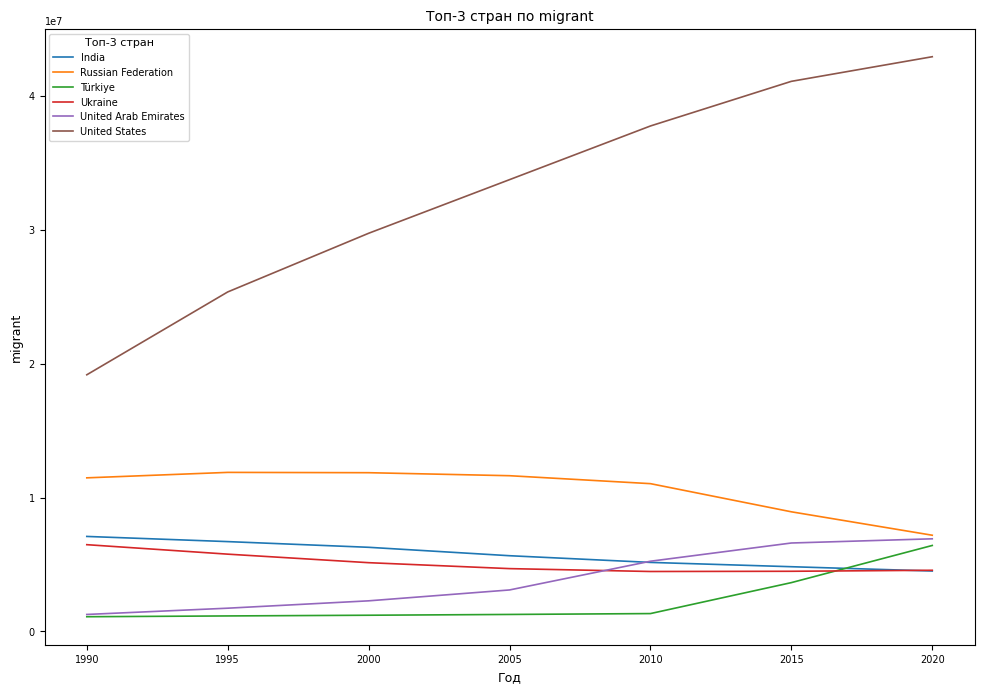

In [1310]:
migrant_df = migrant.load_migrant(YEAR_START, YEAR_END)
migrant_df, migrant_processed_df = migrant.preprocess_migrant(migrant_df, year_start=YEAR_START, rolling_window=5, interpolate=True, logarithmic=True)
#migrant_df.to_csv("../data/basic_preprocessed/migrant_nolog.csv")
#migrant_processed_df.to_csv("../data/preprocessed/migrant_nolog.csv")

In [29]:
migrant_df = pd.read_csv("../data/basic_preprocessed/migrant_nolog.csv").drop('Unnamed: 0', axis=1)
migrant_processed_df = pd.read_csv("../data/preprocessed/migrant_nolog.csv").set_index(['ego', 'alter', 'year'])#.drop('Unnamed: 0', axis=1)

#### Students

In [201]:
#  интерполяция для отсутствующих лет США +
#  экстраполяция для 1985-1998 + (но примитивно, bfill)
#  разобраться с basic_preprocessed +
#  для Китая восстановить данные по Макао и Гонконгу +
#  разобраться, почему нигде в гум нет данных по Германии до 1990 года

INFO:root:Preprocessing students data
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier turks and caicos islands, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier macao, special administrative region of china, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier niue, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier tokelau, replacing with None
  if warning: warnings.warn(f"Unknown identifier {cou

north macedonia Republic of North Macedonia
islamic republic of iran Iran, Islamic Republic of
Cuba Cuba
maldives Maldives
turks and caicos islands None
afghanistan Afghanistan
india India
palestine State of Palestine
macao, special administrative region of china None
singapore Singapore
australia Australia
kuwait Kuwait
montenegro Montenegro
guyana Guyana
latvia Latvia
united kingdom United Kingdom of Great Britain and Northern Ireland
djibouti Djibouti
brazil Brazil
albania Albania
san marino San Marino
papua new guinea Papua New Guinea
ethiopia Ethiopia
gabon Gabon
estonia Estonia
jordan Jordan
eswatini Kingdom of Eswatini
united states United States
liechtenstein Liechtenstein
zimbabwe Zimbabwe
niue None
democratic people's republic of korea Democratic People's Republic of Korea
uzbekistan Uzbekistan
italy Italy
saudi arabia Saudi Arabia
ireland Ireland
liberia Liberia
suriname Suriname
sao tome and principe Sao Tome and Principe
greece Greece
ukraine Ukraine
poland Poland
chad Cha

INFO:root:Extrapolating China data
/home/alex-server/Sync/Работа/Code/phd_thesis/code/data_handling/students.py:33: UserWarning: You are merging on int and float columns where the float values are not equal to their int representation.
  
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier BMU, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier ASM, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:102: UserWarning: Unknown identifier TKL, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/co

LSO Lesotho
MRT Mauritania
NIC Nicaragua
SUR Suriname
MLI Mali
Russian Federation Russian Federation
LAO Lao People's Democratic Republic
GIN Guinea
COD Democratic Republic of the Congo
CPV Cabo Verde
KIR Kiribati
SRB Serbia
TJK Tajikistan
EST Estonia
BTN Bhutan
AFG Afghanistan
GEO Georgia
LIE Liechtenstein
GRC Greece
ARM Armenia
PNG Papua New Guinea
BGR Bulgaria
LVA Latvia
MNG Mongolia
BEL Belgium
BMU None
CRI Costa Rica
EGY Egypt
CUB Cuba
MDG Madagascar
ISR Israel
ZAF South Africa
KWT Kuwait
AUT Austria
ALB Albania
CHE Switzerland
QAT Qatar
BOL Bolivia (Plurinational State of)
KOR Republic of Korea
LCA Saint Lucia
WSM Samoa
PAK Pakistan
MAR Morocco
ASM None
TZA United Republic of Tanzania
POL Poland
COL Colombia
TKL None
AUS Australia
FIN Finland
GAB Gabon
BHR Bahrain
IND India
GUY Guyana
CZE Czechia
VNM Viet Nam
ISL Iceland
NAM Namibia
BLR Belarus
ITA Italy
CMR Cameroon
FRA France
KEN Kenya
DJI Djibouti
JPN Japan
LUX Luxembourg
NER Niger
CHN China, People's Republic of
NZL New Zeala

DEBUG:root:getting all countries for df
DEBUG:data_handling.gsheet_handler:1. try:
DEBUG:root:reading google table country_data, sheet countryids
DEBUG:urllib3.connectionpool:Resetting dropped connection: www.googleapis.com


MDA Republic of Moldova
COM Comoros


DEBUG:urllib3.connectionpool:https://www.googleapis.com:443 "GET /drive/v3/files?q=mimeType%3D%22application%2Fvnd.google-apps.spreadsheet%22+and+name+%3D+%22country_data%22&pageSize=1000&supportsAllDrives=True&includeItemsFromAllDrives=True&fields=kind%2CnextPageToken%2Cfiles%28id%2Cname%2CcreatedTime%2CmodifiedTime%29 HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:Resetting dropped connection: sheets.googleapis.com
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1-A17WUw0EPdt2PFFJAC0F31w7I-jSCuAbmGwc9JWHnQ?includeGridData=false HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1-A17WUw0EPdt2PFFJAC0F31w7I-jSCuAbmGwc9JWHnQ?includeGridData=false HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1-A17WUw0EPdt2PFFJAC0F31w7I-jSCuAbmGwc9JWHnQ/values/%27countryids%27?valueRenderOption=UNFORMATTED_VALUE&dateTimeRenderOption=FORMATTED_STRING HTTP/1.1

Empty DataFrame
Columns: []
Index: [(1985, Afghanistan, Albania), (1986, Afghanistan, Albania), (1987, Afghanistan, Albania), (1988, Afghanistan, Albania), (1989, Afghanistan, Albania), (1990, Afghanistan, Albania), (1991, Afghanistan, Albania), (1992, Afghanistan, Albania), (1993, Afghanistan, Albania), (1994, Afghanistan, Albania), (1995, Afghanistan, Albania), (1996, Afghanistan, Albania), (1997, Afghanistan, Albania), (1998, Afghanistan, Albania), (1985, Afghanistan, Algeria), (1986, Afghanistan, Algeria), (1987, Afghanistan, Algeria), (1988, Afghanistan, Algeria), (1989, Afghanistan, Algeria), (1990, Afghanistan, Algeria), (1991, Afghanistan, Algeria), (1992, Afghanistan, Algeria), (1993, Afghanistan, Algeria), (1994, Afghanistan, Algeria), (1995, Afghanistan, Algeria), (1996, Afghanistan, Algeria), (1997, Afghanistan, Algeria), (1998, Afghanistan, Algeria), (1985, Afghanistan, Andorra), (1986, Afghanistan, Andorra), (1987, Afghanistan, Andorra), (1988, Afghanistan, Andorra), (198

INFO:root:Done preprocessing students Data (COMstudents)


                              value
year ego         alter             
1985 Congo       Peru      0.000000
     Mozambique  Peru      0.000003
     Liberia     Peru      0.000000
     Albania     Peru      0.000000
     Rwanda      Peru      0.000003
...                             ...
2022 Uruguay     Kiribati  0.000000
     Australia   Kiribati  0.000125
     New Zealand Kiribati  0.000126
     Timor-Leste Kiribati  0.000000
     Lesotho     Kiribati  0.000000

[1616022 rows x 1 columns]
                              value
year ego         alter             
1985 Congo       Peru      0.000000
     Mozambique  Peru      0.000003
     Liberia     Peru      0.000000
     Albania     Peru      0.000000
     Rwanda      Peru      0.000003
...                             ...
2022 Uruguay     Kiribati  0.000000
     Australia   Kiribati  0.000125
     New Zealand Kiribati  0.000126
     Timor-Leste Kiribati  0.000000
     Lesotho     Kiribati  0.000000

[1616022 rows x 1 columns]


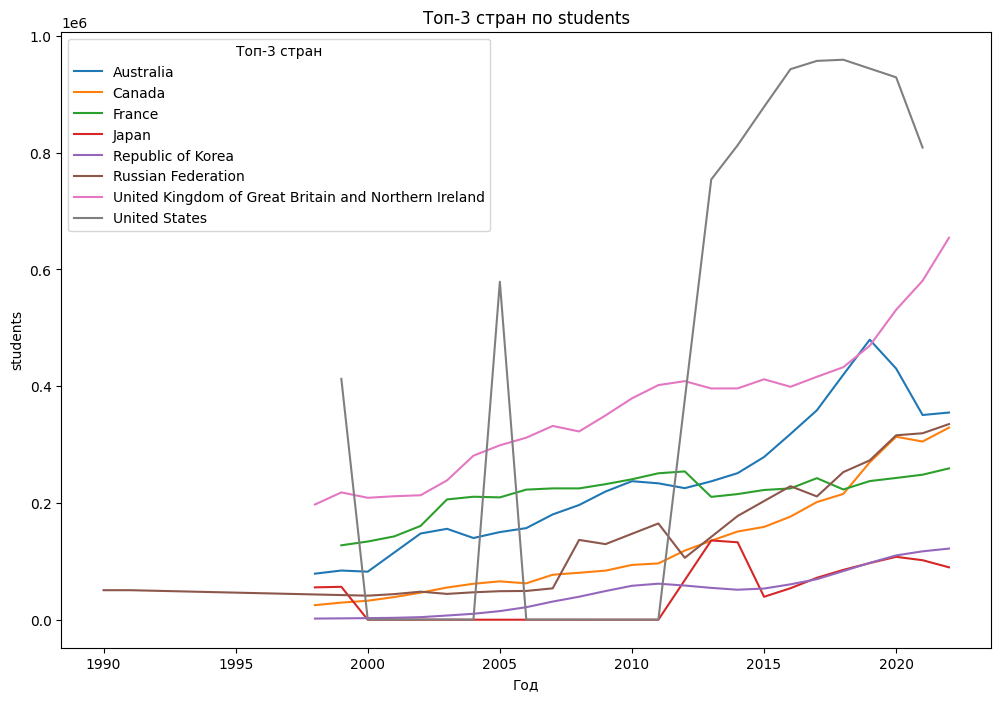

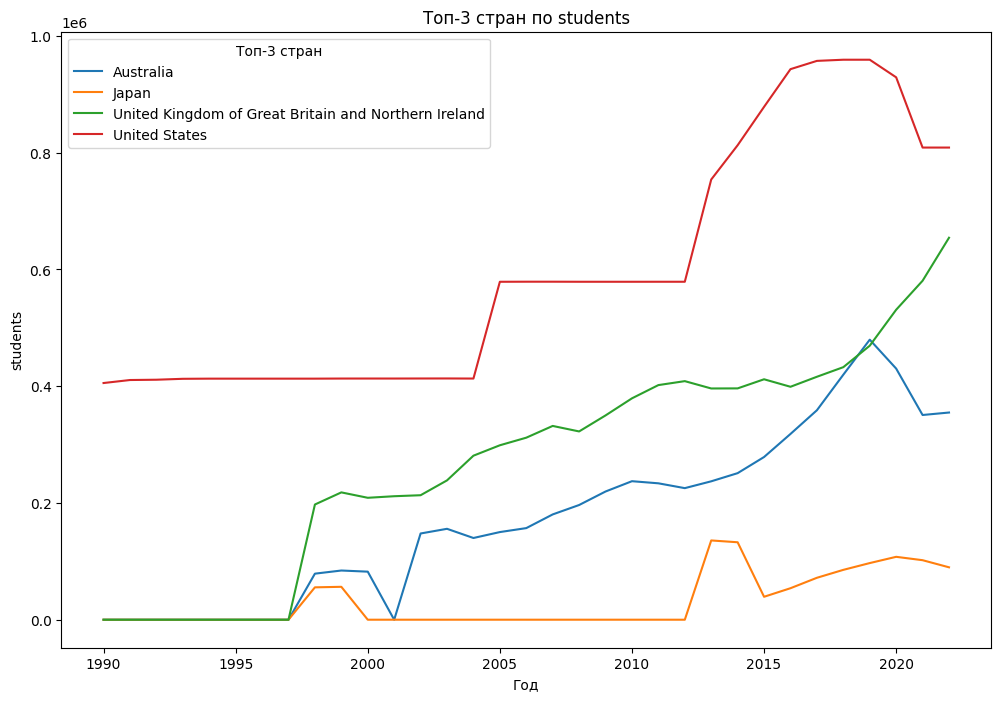

In [1098]:
students_df = students.load_students()
students_df, students_processed_df = students.preprocess_students(students_df, year_start=YEAR_START, rolling_window=5, interpolate=True, extrapolate=True)
students_df.to_csv("../data/basic_preprocessed/students_after.csv")
students_processed_df.to_csv("../data/preprocessed/students.csv")

In [30]:
students_df = pd.read_csv("../data/basic_preprocessed/students_after.csv").drop('Unnamed: 0', axis=1)
students_processed_df = pd.read_csv("../data/preprocessed/students.csv").set_index(['ego', 'alter', 'year'])#.drop('Unnamed: 0', axis=1)

#### Tourism

In [ ]:
# Non-vector

#### ODA/Foreign Aid

In [31]:
oda_df = pd.read_csv("../data/basic_preprocessed/oda.csv")
oda_processed_df = pd.read_csv("../data/preprocessed/oda.csv").set_index(['ego', 'alter', 'year'])

/tmp/ipykernel_6134/1507100309.py:1: DtypeWarning: Columns (0: Type, 1: Note) have mixed types. Specify dtype option on import or set low_memory=False.
  oda_df = pd.read_csv("../data/basic_preprocessed/oda.csv")


#### UN Resolutions

/home/alex-server/Sync/Работа/Code/phd_thesis/code/data_handling/humanun.py:17: DtypeWarning: Columns (0: vote_status) have mixed types. Specify dtype option on import or set low_memory=False.
  humanun_df_in = pd.read_csv(humanun_PATH, index_col = 'Unnamed: 0')
INFO:root:Preprocessing humanun data


Rwanda Rwanda
Liberia Liberia
Russia Russian Federation
Equatorial Guinea Equatorial Guinea
Angola Angola
Albania Albania
Haiti Haiti
Cuba Cuba
Sierra Leone Sierra Leone
Kyrgyzstan Kyrgyzstan
South Sudan South Sudan
Cambodia Cambodia
Uganda Uganda
Bosnia and Herzegovina Bosnia and Herzegovina
Guinea Guinea
Burundi Burundi
Russian Federation Russian Federation
Zaire Democratic Republic of the Congo
Sudan Sudan
Venezuela Venezuela (Bolivarian Republic of)
Yemen Yemen
Libya Libya
Tunisia Tunisia
Somalia Somalia
Central African Republic Central African Republic
Sri Lanka Sri Lanka
Guatemala Guatemala
South Africa South Africa
Syria Syrian Arab Republic
Palestinian State of Palestine
Turkmenistan Turkmenistan
Eritrea Eritrea
Iran Iran, Islamic Republic of
Iraq Iraq
Romania Romania
East Timor Timor-Leste
Syrian Arab Republic Syrian Arab Republic
Philippines Philippines
Papua New Guinea Papua New Guinea
Marshall Islands Marshall Islands
Ukraine Ukraine
Palestine State of Palestine
Lebanon Leb

DEBUG:root:getting all countries for df
DEBUG:data_handling.gsheet_handler:1. try:
DEBUG:root:reading google table country_data, sheet countryids
DEBUG:urllib3.connectionpool:Resetting dropped connection: oauth2.googleapis.com


Poland Poland
Côte d’Ivoire Côte d'Ivoire
Uganda Uganda
South Sudan South Sudan
Bulgaria Bulgaria
Burundi Burundi
Zimbabwe Zimbabwe
Dominican Republic Dominican Republic
Malta Malta
Yemen Yemen
Guinea-Bissau Guinea-Bissau
Somalia Somalia
North Macedonia Republic of North Macedonia
Algeria Algeria
Denmark Denmark
Namibia Namibia
Iran Iran, Islamic Republic of
Slovenia Slovenia
Barbados Barbados
Saudi Arabia Saudi Arabia
Estonia Estonia
Singapore Singapore
Micronesia Micronesia (Federated States of)
Marshall Islands Marshall Islands
Portugal Portugal
Ukraine Ukraine
Lebanon Lebanon
Ghana Ghana
Thailand Thailand
El Salvador El Salvador
Nigeria Nigeria
Palau Palau
Yugoslavia Serbia
Malawi Malawi
Republic of Moldova Republic of Moldova
Paraguay Paraguay
Monaco Monaco
Bosnia Bosnia and Herzegovina
Serbia Serbia
Jordan Jordan
Austria Austria
Pakistan Pakistan
Liechtenstein Liechtenstein
Djibouti Djibouti
United Kingdom United Kingdom of Great Britain and Northern Ireland
Japan Japan
Sudan Sud

DEBUG:urllib3.connectionpool:https://oauth2.googleapis.com:443 "POST /token HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:Resetting dropped connection: www.googleapis.com
DEBUG:urllib3.connectionpool:https://www.googleapis.com:443 "GET /drive/v3/files?q=mimeType%3D%22application%2Fvnd.google-apps.spreadsheet%22+and+name+%3D+%22country_data%22&pageSize=1000&supportsAllDrives=True&includeItemsFromAllDrives=True&fields=kind%2CnextPageToken%2Cfiles%28id%2Cname%2CcreatedTime%2CmodifiedTime%29 HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:Resetting dropped connection: sheets.googleapis.com
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1-A17WUw0EPdt2PFFJAC0F31w7I-jSCuAbmGwc9JWHnQ?includeGridData=false HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 "GET /v4/spreadsheets/1-A17WUw0EPdt2PFFJAC0F31w7I-jSCuAbmGwc9JWHnQ?includeGridData=false HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://sheets.googleapis.com:443 

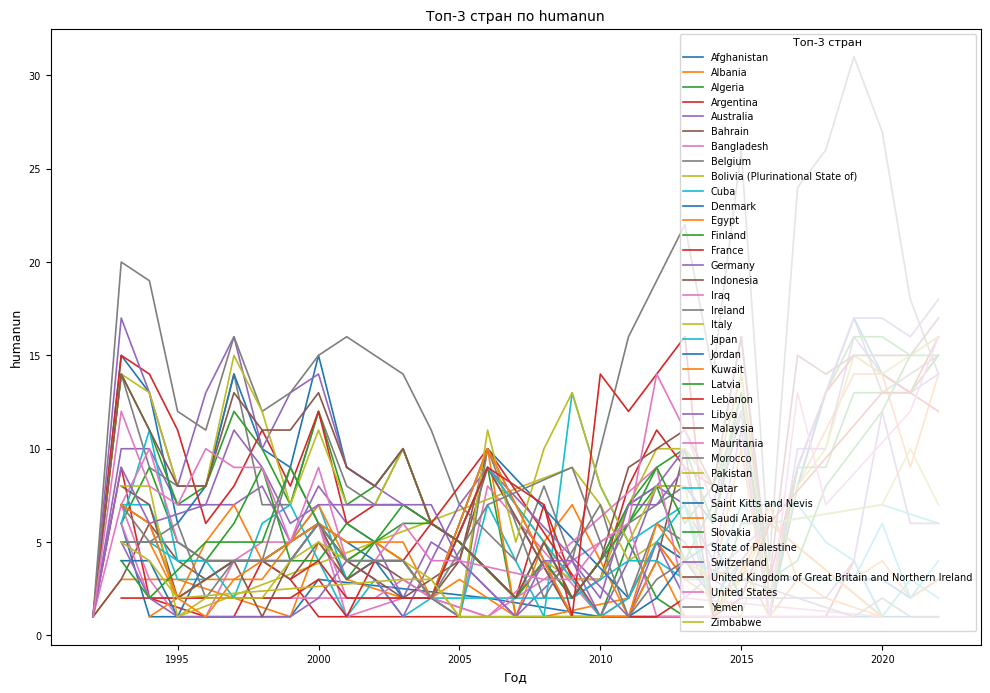

In [1357]:
humanun_df = humanun.load_humanun()
humanun_df, humanun_processed_df = humanun.preprocess_humanun(humanun_df, year_start=YEAR_START, year_end=YEAR_END, rolling_window=5, normalize=True, extrapolate=True)
humanun_df.to_csv("../data/basic_preprocessed/humanun.csv")
humanun_processed_df.to_csv("../data/preprocessed/humanun.csv")

In [32]:
humanun_df = pd.read_csv("../data/basic_preprocessed/humanun.csv")
humanun_processed_df = pd.read_csv("../data/preprocessed/humanun.csv").set_index(['ego', 'alter', 'year'])

#### Humanitarian conjoined

In [555]:
# MIGRANT - почему штаты не первые? - из-за лог шкалы
# REFUGEE - почему Иран Турция не первые? - из-за лог шкалы

In [732]:
test_sphere(human_dfs, years = [2022])

{'migrant':                                                  ego        value
 0                                              Spain  1014.241744
 1                               United Arab Emirates  1032.277109
 2                                 Russian Federation  1072.155353
 3                                          Australia  1107.864656
 4  United Kingdom of Great Britain and Northern I...  1136.449289
 5                                             France  1164.118717
 6                                             Canada  1178.739332
 7                                            Germany  1664.223108
 8                                       Saudi Arabia  1857.723909
 9                                      United States  6401.814960,
 'refugee':                          ego        value
 0                 Bangladesh  2374.569433
 1                     Poland  2428.338369
 2                      Sudan  2814.748677
 3         Russian Federation  3188.057078
 4                     Ug

INFO:root:saving figure
INFO:root:saving figure
INFO:root:saving figure
INFO:root:saving figure
INFO:root:saving figure


{'migrant':                                                  ego          value
0  United Kingdom of Great Britain and Northern I...   36132.789493
1                                          Australia   41523.702397
2                                             Canada   46847.177797
3                                           Pakistan   48862.061479
4                                       Saudi Arabia   52731.760572
5                                            Germany   55468.026578
6                                             France   56976.368672
7                                 Russian Federation   57335.927112
8                                              India   61921.281974
9                                      United States  247504.309160, 'refugee':                                 ego          value
0       United Republic of Tanzania   36169.906208
1  Democratic Republic of the Congo   37606.705613
2                          Ethiopia   39165.762902
3                       

INFO:root:saving figure


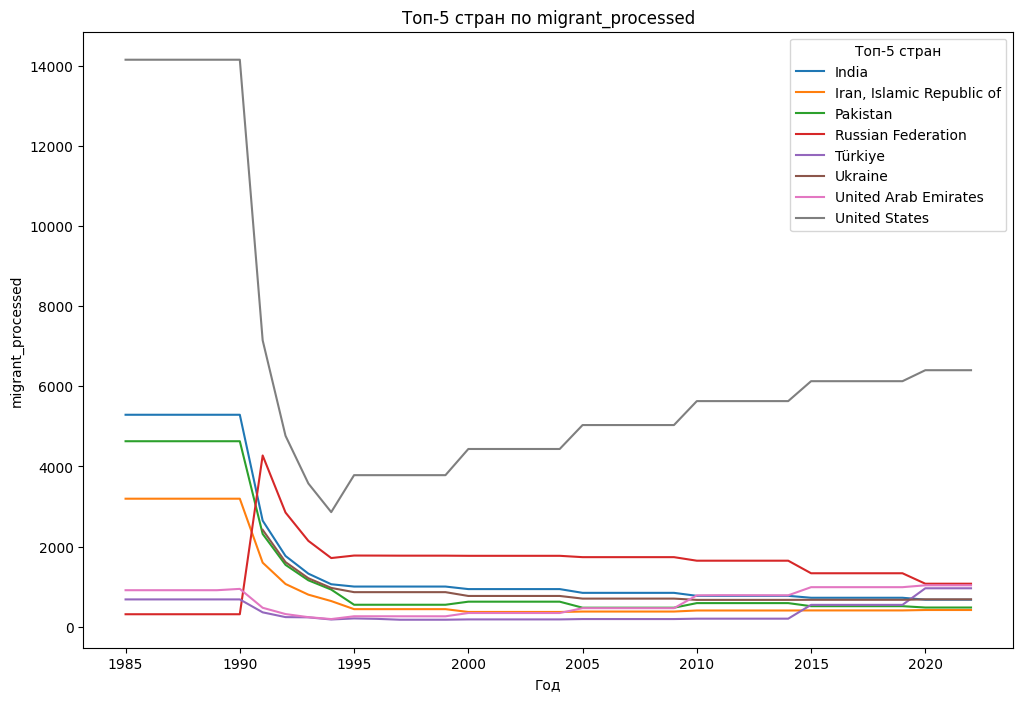

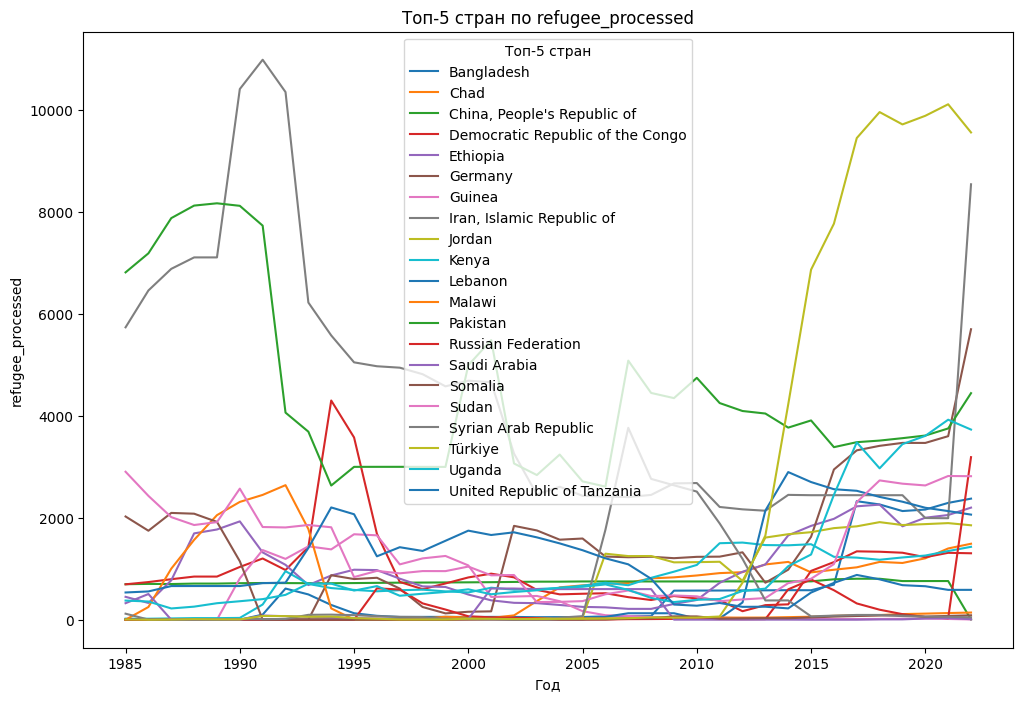

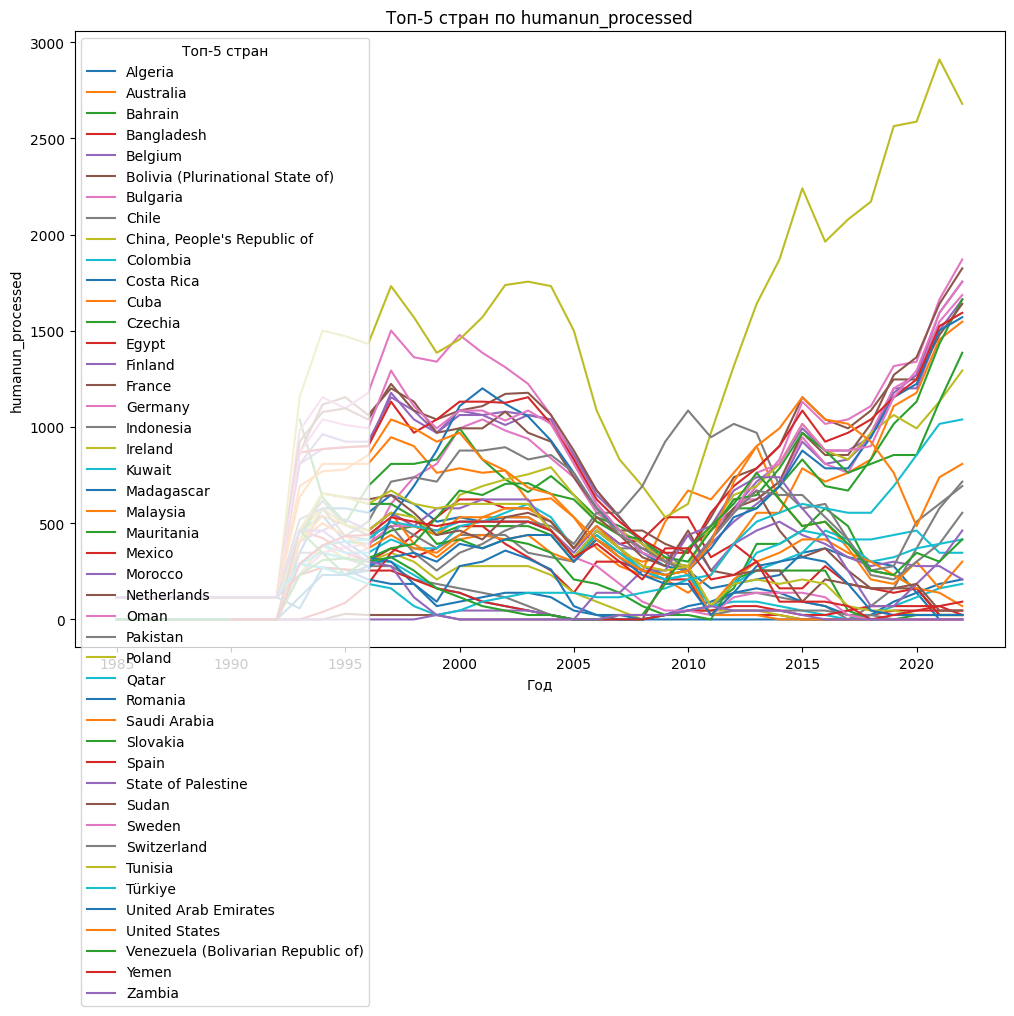

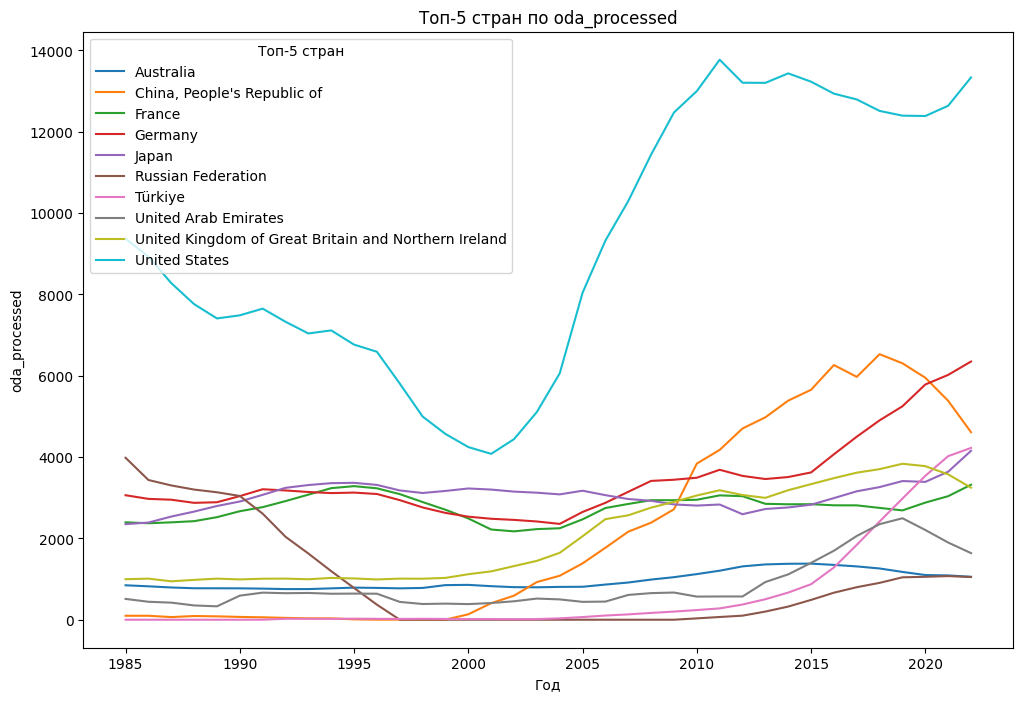

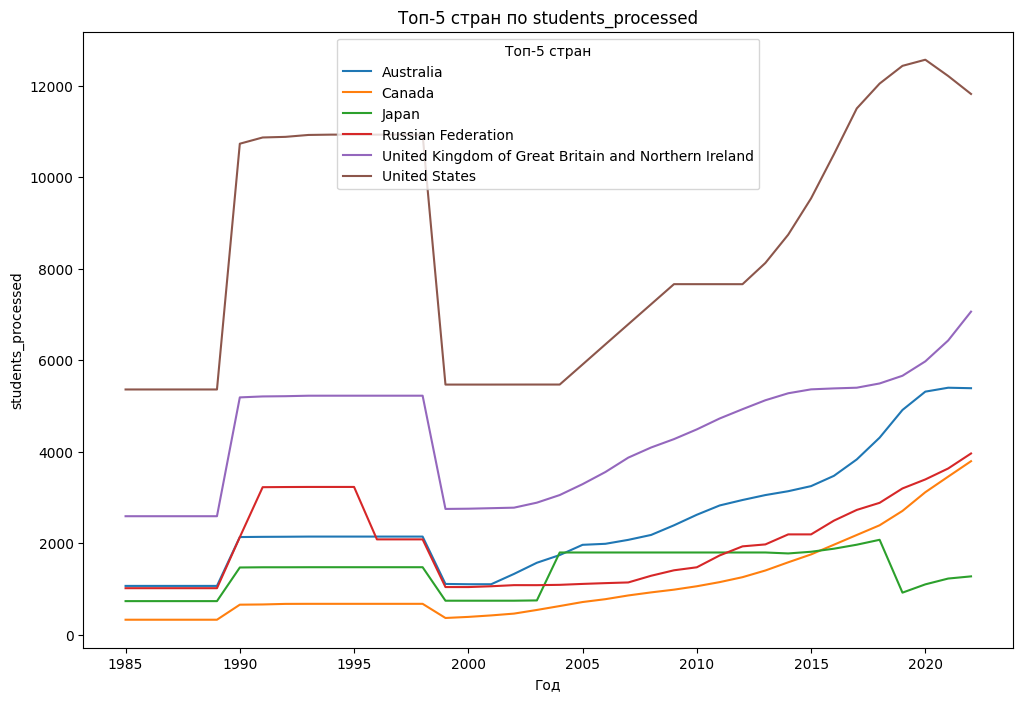

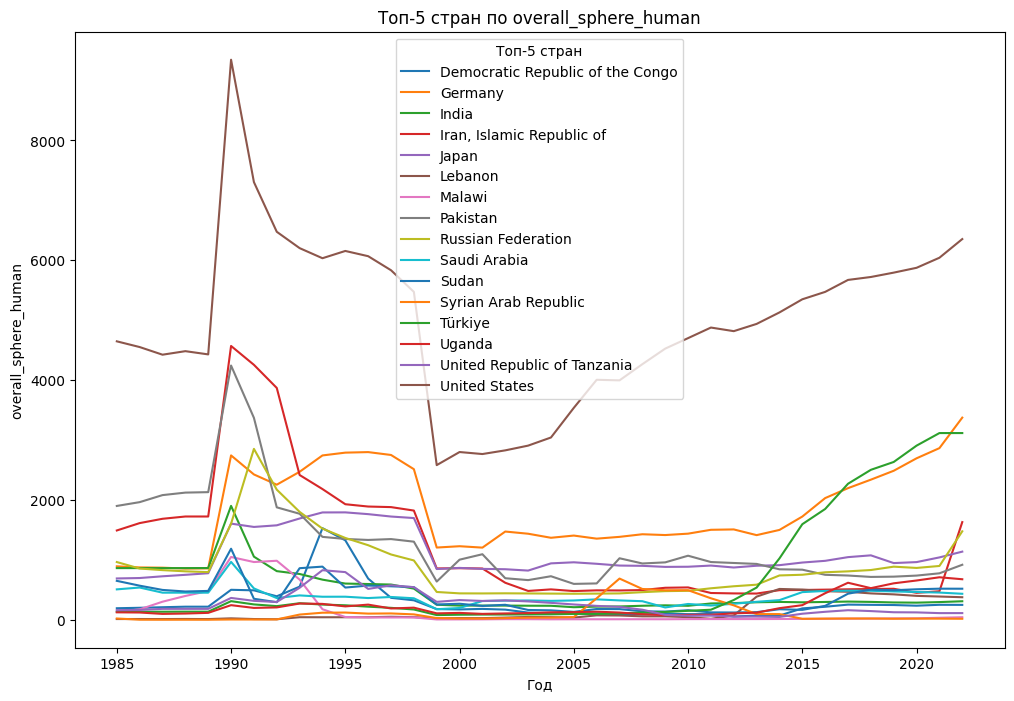

In [35]:
human_dfs = {
    'migrant':migrant_processed_df,
    'refugee':refugee_processed_df,
    'humanun':humanun_processed_df,
    'oda':oda_processed_df,
    'students' :students_processed_df
}
human_triple = merge_sphere(human_dfs, HUMAN_WEIGHTS, test=True, label='human')

### Overall (Politics)

#### Diplomatic visits

INFO:root:Loaded Visits COLT Database
INFO:root:Preprocessing visits data
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:101: UserWarning: Unknown identifier XLX, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:101: UserWarning: Unknown identifier YAR, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:101: UserWarning: Unknown identifier XAX, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:101: UserWarning: Unknown identifier ESH, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_m

BEL Belgium
FSM Micronesia (Federated States of)
ZMB Zambia
URY Uruguay
RWA Rwanda
KGZ Kyrgyzstan
WSM Samoa
HUN Hungary
SGP Singapore
NGA Nigeria
ZWE Zimbabwe
VEN Venezuela (Bolivarian Republic of)
VUT Vanuatu
CIV Côte d'Ivoire
IRL Ireland
HND Honduras
LCA Saint Lucia
SYR Syrian Arab Republic
PSE State of Palestine
GNB Guinea-Bissau
GUY Guyana
GHA Ghana
SMR San Marino
XLX None
YAR None
SYC Seychelles
MYS Malaysia
MHL Marshall Islands
IRN Iran, Islamic Republic of
ARM Armenia
DZA Algeria
JAM Jamaica
SWE Sweden
MUS Mauritius
DOM Dominican Republic
TUV Tuvalu
BIH Bosnia and Herzegovina
FRA France
AZE Azerbaijan
BDI Burundi
SDN Sudan
SVK Slovakia
KIR Kiribati
XAX None
USA United States
HTI Haiti
SAU Saudi Arabia
DNK Denmark
BLR Belarus
MMR Myanmar
NZL New Zealand
DEU Germany
NLD Netherlands
UGA Uganda
ESH None
BTN Bhutan
SLB Solomon Islands
AUS Australia
QAT Qatar
SWZ Kingdom of Eswatini
KHM Cambodia
XNC None
GAB Gabon
AND Andorra
BGD Bangladesh
NOR Norway
FRG None
XKX None
NIC Nicaragua
G

/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:101: UserWarning: Unknown identifier XAN, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:101: UserWarning: Unknown identifier XEC, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:101: UserWarning: Unknown identifier XIB, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/countryconverter.py:101: UserWarning: Unknown identifier FRG, replacing with None
  if warning: warnings.warn(f"Unknown identifier {country}, replacing with {replace_missing}")
/home/alex-server/Sync/Работа/Code/phd_thesis/code/utils/country

BEL Belgium
FSM Micronesia (Federated States of)
ZMB Zambia
URY Uruguay
RWA Rwanda
KGZ Kyrgyzstan
WSM Samoa
HUN Hungary
SGP Singapore
NGA Nigeria
VEN Venezuela (Bolivarian Republic of)
VUT Vanuatu
ZWE Zimbabwe
CIV Côte d'Ivoire
IRL Ireland
HND Honduras
LCA Saint Lucia
UZB Uzbekistan
SYR Syrian Arab Republic
PSE State of Palestine
GNB Guinea-Bissau
GUY Guyana
GHA Ghana
SMR San Marino
SYC Seychelles
MYS Malaysia
MHL Marshall Islands
ARM Armenia
DZA Algeria
JAM Jamaica
PLW Palau
MUS Mauritius
SWE Sweden
DOM Dominican Republic
XAN None
TUV Tuvalu
BIH Bosnia and Herzegovina
FRA France
XEC None
AZE Azerbaijan
BDI Burundi
SVK Slovakia
SDN Sudan
KIR Kiribati
USA United States
HTI Haiti
SAU Saudi Arabia
DNK Denmark
BLR Belarus
MMR Myanmar
NZL New Zealand
DEU Germany
NLD Netherlands
UGA Uganda
BTN Bhutan
SLB Solomon Islands
AUS Australia
QAT Qatar
KHM Cambodia
AND Andorra
SWZ Kingdom of Eswatini
GAB Gabon
XIB None
BGD Bangladesh
NOR Norway
FRG None
XKX None
XMF None
NIC Nicaragua
MlI Mali
GNQ Eq

/home/alex-server/Sync/Работа/Code/phd_thesis/code/data_handling/visits.py:60: FutureWarning: The default value of numeric_only in DataFrameGroupBy.sum is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  df_triple = df.groupby([YEAR_LABEL, EGO_LABEL, ALTER_LABEL]).sum()
INFO:root:Testing initiated
INFO:root:Missing 2(194/196 = (0.9897959183673469)) egos, 3(193/196 = 0.9846938775510204) alters, 3 years
INFO:root:Missing egos: {'German Democratic Republic', 'Czechoslovakia'}
INFO:root:Missing great egos: set()
INFO:root:Missing alters: {'German Democratic Republic', 'Czechoslovakia', 'Iran, Islamic Republic of'}
INFO:root:Missing great alters: set()
INFO:root:Missing years: {1985, 1986, 1987, 1988, 1989}
INFO:root:1311926 - 53989 = 1257937 lines missing (0.04115247353890387)
INFO:root:                                   0
Source name                   visits
Missing egos       

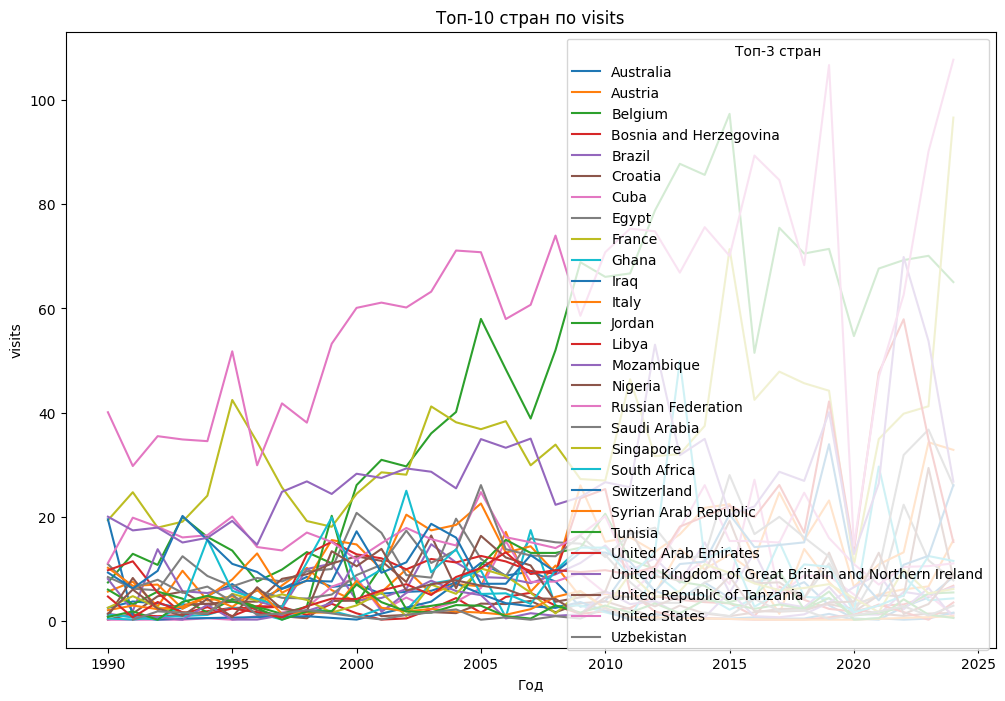

In [37]:
visits_df = visits.load_visits()
visits_df, visits_processed_df = visits.preprocess_visits(visits_df, year_start=YEAR_START, year_end=YEAR_END, rolling_window=5, normalize=True)
visits_df.to_csv("../data/basic_preprocessed/visits.csv")
visits_processed_df.to_csv("../data/preprocessed/visits.csv")

In [99]:
visits_df = pd.read_csv("../data/basic_preprocessed/visits.csv")#.drop('Unnamed: 0', axis=1)
visits_processed_df = pd.read_csv("../data/preprocessed/visits.csv").set_index(['ego', 'alter', 'year'])#.drop('Unnamed: 0', axis=1)

/tmp/ipykernel_3696017/1289638255.py:1: DtypeWarning: Columns (0: TripDuration, 1: CotravelHOGS, 2: HostSubHOGSName, 3: SourceLink14, 4: SourceLink15, 5: SourceLink16, 6: SourceLink17, 7: SourceLink18, 8: SourceLink19, 9: SourceLink20, 10: SourceLink21, 11: SourceLink22, 12: SourceLink23, 13: SourceLink24, 14: SourceLink25, 15: SourceLink26, 16: SourceLink27, 17: SourceLink28, 18: SourceLink29, 19: SourceLink30, 20: SourceLink31, 21: SourceLink32, 22: SourceLink33) have mixed types. Specify dtype option on import or set low_memory=False.
  visits_df = pd.read_csv("../data/basic_preprocessed/visits.csv")#.drop('Unnamed: 0', axis=1)


# Network Analysis

## Constructing network

#### Testing

In [ ]:
# Почему для Белорусии и России security нет

In [481]:
mask = (economy_triple.reset_index()['ego']=='Czechia')&(economy_triple.reset_index()['year']==2022)
economy_triple.reset_index().loc[mask].sort_values('value').sum()

year                                                390246
alter    MonacoTuvaluSolomon IslandsDemocratic People's...
ego      CzechiaCzechiaCzechiaCzechiaCzechiaCzechiaCzec...
value                                           814.053371
dtype: object

In [734]:
economy_triple.drop('index', axis=1, inplace=True)

##### Strong connectivity

In [1355]:
# need to compute subsystems first
for sphere in subsystems:
    for year in range(YEAR_START, YEAR_END+1):
        g = subsystems[sphere]['networks'][year] 
        print(sphere, year, nx.is_strongly_connected(g))

security 1985 False
security 1986 False
security 1987 False
security 1988 False
security 1989 False
security 1990 False
security 1991 False
security 1992 False
security 1993 False
security 1994 False
security 1995 False
security 1996 False
security 1997 False
security 1998 False
security 1999 False
security 2000 False
security 2001 False
security 2002 False
security 2003 False
security 2004 False
security 2005 False
security 2006 False
security 2007 False
security 2008 False
security 2009 False
security 2010 False
security 2011 False
security 2012 False
security 2013 False
security 2014 False
security 2015 False
security 2016 False
security 2017 False
security 2018 False
security 2019 False
security 2020 False
security 2021 False
security 2022 False
economy 1985 False
economy 1986 False
economy 1987 False
economy 1988 False
economy 1989 False
economy 1990 False
economy 1991 False
economy 1992 False
economy 1993 False
economy 1994 False
economy 1995 False
economy 1996 False
economy 1997

#### Main

In [1125]:
## Translation

In [36]:
if RUSSIFY_VISUALS:
    df = human_triple.reset_index().drop_duplicates(subset='ego').copy()
    df['ego_en'] = df['ego']
    df = convert_country_df(df.reset_index(), data_id_col='ego', standard_to_convert='STATE_ru', print_convertions=False)
    translation_dict = df.set_index('ego_en', drop=True)[['ego']].to_dict()['ego']

In [37]:
if RUSSIFY_VISUALS:
    security_triple=security_triple.reset_index().replace(translation_dict).set_index(['year', 'alter', 'ego'])
    economy_triple=economy_triple.reset_index().replace(translation_dict).set_index(['year', 'alter', 'ego'])
    human_triple=human_triple.reset_index().replace(translation_dict).set_index(['year', 'alter', 'ego'])

In [38]:
# DATA ANSLYSIS
processed_dfs = {
    'security' : security_triple.fillna(0),
    'economy' : economy_triple.fillna(0),
    'human' : human_triple.fillna(0)
}
centrality_types = {
    'security' : 'reverse_pagerank',#'reverse_pagerank',
    'economy' : 'reverse_pagerank',#'betweenness',
    'human' : 'reverse_pagerank',#'betweenness'
}
for sphere in processed_dfs:
    if centrality_types[sphere] == 'betweenness':
        processed_dfs[sphere]['value'] = (processed_dfs[sphere]['value']*100).astype(int) #  for betweenness centrality

analysis, subsystems = analyse_system(processed_dfs, print_trace=False,
                                      year_start=YEAR_START, year_end=YEAR_END, 
                                      centrality_type=centrality_types, count_abs=False
                                      )
#analysis, subsystems = analyse_system(processed_dfs, print_trace=True,
#                                      year_start=YEAR_START, year_end=YEAR_END, 
#                                      centrality_type='reverse_pagerank', count_abs=False)

# node, G = analyse_system(processed_dfs, year_start=YEAR_START, year_end=YEAR_END, centrality_type='out-degree-weighted')
# analysis, subsystems = analyse_system(processed_dfs, year_start=YEAR_START, year_end=YEAR_END, centrality_type='katz', count_abs=True)
# katz - не подходит для полных сетей
# eigenvector - если мои друзья влиятельны, то и я буду более влиятельным. Не работает. Так как связи с изолированными тоже дает влияние
# betweenness centrality - для роли посредничества.
# random_walk_betweenness - не учитывает направление связей
# communicability - не учитывает веса связей
# trophic levels - не учитывает веса связей
# closeness vitality - слишком нестабильные результаты, графы не являются сильно связанными

logging.info(f"Веса: {SUBSYSTEM_WEIGHTS}")
analysis_weighted = analysis.fillna(0).groupby(['ego', 'year']).centrality.agg(lambda x: row_geometric_mean(
    row=x, subsystem_weights=SUBSYSTEM_WEIGHTS, print_rows=False))
analysis = analysis.set_index(['ego', 'year'])
analysis['weighted_centrality'] = analysis_weighted
analysis = analysis.reset_index()

status_combined = combine_spheres(analysis)
analysis=analysis.reset_index(drop=True)

INFO:root:Analysing security
INFO:root:there are 196 unique countries, 196 - ego, 196 - alter
INFO:root:Getting global networks for 1985 - 2022


done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done


INFO:root:Done getting networks


done
done
done
done
done
done
done
done
done
done
done


INFO:root:Analysing economy
INFO:root:there are 196 unique countries, 196 - ego, 196 - alter
INFO:root:Getting global networks for 1985 - 2022


...

INFO:root:Analysing human
INFO:root:there are 196 unique countries, 196 - ego, 196 - alter
INFO:root:Getting global networks for 1985 - 2022


done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done
done


INFO:root:Done getting networks


done


INFO:root:Веса: {'human': 0.2422192151556157, 'economy': 0.32476319350473615, 'security': 0.43301759133964823}


#### Saving

In [39]:
analysis.to_csv('../data/analysis.csv')
analysis.to_excel('../data/analysis.xlsx')
status_combined.to_csv('../data/status_combined.csv')

for subsystem, y in product(SUBSYSTEMS, range(YEAR_START, YEAR_END+1)):
    nx.write_weighted_edgelist(subsystems[subsystem]['networks'][y], f'../data/networks/n_{subsystem}_{y}.nx', comments='#', delimiter='|', encoding='utf-8')
    nx.write_graphml_lxml(subsystems[subsystem]['networks'][y], f'../data/networks/graphml/n_{subsystem}_{y}.lxml')
for subsystem in SUBSYSTEMS:
    subsystems[subsystem]['data'].to_csv(f'../data/preprocessed/subsystem_level/df_{subsystem}_{y}.csv')

#### Loading

In [9]:
analysis=pd.read_csv('../data/analysis.csv', index_col='Unnamed: 0')
status_combined=pd.read_csv('../data/status_combined.csv')

subsystems=read_subsystems(year_start=1985)

INFO:root:Сканируем папку: /home/alex-server/Sync/Работа/Code/phd_thesis/data/preprocessed/subsystem_level
INFO:root:Содержимое папки (4 элементов):
INFO:root:  - df_economy_2022.csv
INFO:root:  - df_security_2022.csv
INFO:root:  - df_human_2022.csv
INFO:root:  - .ipynb_checkpoints
INFO:root:Добавлена категория: 'economy' из файла df_economy_2022.csv
INFO:root:Добавлена категория: 'security' из файла df_security_2022.csv
INFO:root:Добавлена категория: 'human' из файла df_human_2022.csv
INFO:root:Найдено уникальных категорий: 3
INFO:root:Итоговый список категорий: ['economy', 'human', 'security']
INFO:root:reading subsystems ['economy', 'human', 'security']


In [57]:
# США-Гренада в экономике в 1995? Инвестиции. Сомнительно

## Топология

#### Средняя сетевая связность (сколько связей в среднем приходится на один узел)

In [ ]:
# very_slow
av_connectivity = dict()
for sphere in subsystems:
    av_connectivity[sphere] = dict()
    for y in range (YEAR_START, YEAR_END+1):
        logging.info(f"Getting av connectivity for {sphere}, {y}")
        av_connectivity[sphere][y] = nx.average_node_connectivity(subsystems[sphere]['networks'][y])

av_connectivity_df = pd.DataFrame(pd.DataFrame(av_connectivity).unstack()).reset_index().rename({'level_0':'sphere', 'level_1':'year', 0:'avg_connectivity'}, axis=1)

In [ ]:
# Save
av_connectivity_df.to_csv(f'../data/networks/av_connectivity/av_connectivity.csv')

In [10]:
# Load
av_connectivity_df = pd.read_csv(f'../data/networks/av_connectivity/av_connectivity.csv', index_col='Unnamed: 0')

In [11]:
av_connectivity_df.groupby('sphere').mean()

,year,avg_connectivity
sphere,,
economy,2003.5,64.141078
human,2003.5,49.586846
security,2003.5,0.378460


DEBUG:matplotlib.ticker:vmin 0.060330064373191786 vmax 149.2109288034071
DEBUG:matplotlib.ticker:ticklocs array([1.e-03, 1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02, 1.e+03, 1.e+04])
DEBUG:matplotlib.ticker:vmin 0.060330064373191786 vmax 149.2109288034071
DEBUG:matplotlib.ticker:ticklocs array([2.e-03, 3.e-03, 4.e-03, 5.e-03, 6.e-03, 7.e-03, 8.e-03, 9.e-03,
       2.e-02, 3.e-02, 4.e-02, 5.e-02, 6.e-02, 7.e-02, 8.e-02, 9.e-02,
       2.e-01, 3.e-01, 4.e-01, 5.e-01, 6.e-01, 7.e-01, 8.e-01, 9.e-01,
       2.e+00, 3.e+00, 4.e+00, 5.e+00, 6.e+00, 7.e+00, 8.e+00, 9.e+00,
       2.e+01, 3.e+01, 4.e+01, 5.e+01, 6.e+01, 7.e+01, 8.e+01, 9.e+01,
       2.e+02, 3.e+02, 4.e+02, 5.e+02, 6.e+02, 7.e+02, 8.e+02, 9.e+02,
       2.e+03, 3.e+03, 4.e+03, 5.e+03, 6.e+03, 7.e+03, 8.e+03, 9.e+03,
       2.e+04, 3.e+04, 4.e+04, 5.e+04, 6.e+04, 7.e+04, 8.e+04, 9.e+04])
DEBUG:matplotlib.ticker:vmin 0.060330064373191786 vmax 149.2109288034071
DEBUG:matplotlib.ticker:ticklocs array([1.e-03, 1.e-02, 1.e-01, 1.e+00, 1.

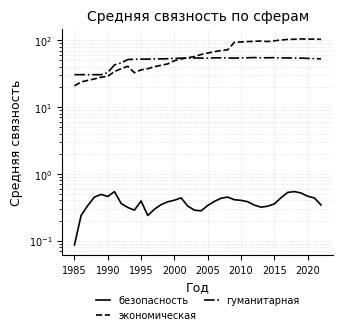

In [1393]:
# Настройки для ч/б печати
plt.rcParams.update({
    'font.size': 8,
    'axes.labelsize': 9,
    'axes.titlesize': 10,
    'legend.fontsize': 7,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'lines.linewidth': 1.2,
    'axes.linewidth': 0.8,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
})

# Список стилей линий – только различные пунктиры
line_styles = [
    '-',                      # сплошная
    '--',                     # штриховая
    '-.',                     # штрих-пунктирная
    ':',                      # пунктирная
    (0, (5, 2)),              # редкий пунктир
    (0, (3, 1, 1, 1)),        # точка-тире
    (0, (4, 2, 1, 2)),        # сложный пунктир
    (0, (1, 1)),              # очень частый пунктир
]

# Получаем список сфер в порядке их появления
spheres = av_connectivity_df['sphere'].unique()

# Компактная фигура с местом для легенды снизу
fig, ax = plt.subplots(figsize=(3.5, 3.6))

for i, sphere in enumerate(spheres):
    # Выбираем данные для конкретной сферы
    df_sphere = av_connectivity_df[av_connectivity_df['sphere'] == sphere]
    # Сортируем по году (на случай, если данные не упорядочены)
    df_sphere = df_sphere.sort_values('year')
    
    # Стиль линии
    style = line_styles[i % len(line_styles)]
    
    # Строим линию без маркеров
    ax.plot(
        df_sphere['year'], df_sphere['avg_connectivity'],
        linestyle=style,
        color='black',
        label=SUBSYSTEMS_RU[sphere]
    )

# Логарифмическая шкала по Y для отображения сильно различающихся величин
ax.set_yscale('log')

# Оформление осей
ax.set_title('Средняя связность по сферам')
ax.set_xlabel('Год')
ax.set_ylabel('Средняя связность')
ax.grid(True, which='both', linestyle=':', linewidth=0.5, color='lightgray')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Легенда размещена под графиком, горизонтально, без рамки
ax.legend(
    loc='upper center',          # отправная точка для bbox_to_anchor
    bbox_to_anchor=(0.5, -0.15), # сдвиг вниз от нижней границы осей
    ncol=2,                      # два столбца для компактности
    frameon=False,
    handlelength=1.5,
    columnspacing=0.8,
    borderaxespad=0.2
)

# Ручная настройка полей, чтобы легенда не обрезалась
plt.subplots_adjust(bottom=0.25)

# Сохранение с высоким разрешением
plt.savefig(f'../output/avg_connectivity_log{"_grey" if PLOT_GREY else ""}.png', dpi=300, bbox_inches='tight')
plt.show()

DEBUG:matplotlib.ticker:vmin 0.062348622112114144 vmax 74.7560135543772
DEBUG:matplotlib.ticker:ticklocs array([1.e-03, 1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02, 1.e+03])
DEBUG:matplotlib.ticker:vmin 0.062348622112114144 vmax 74.7560135543772
DEBUG:matplotlib.ticker:ticklocs array([2.e-03, 3.e-03, 4.e-03, 5.e-03, 6.e-03, 7.e-03, 8.e-03, 9.e-03,
       2.e-02, 3.e-02, 4.e-02, 5.e-02, 6.e-02, 7.e-02, 8.e-02, 9.e-02,
       2.e-01, 3.e-01, 4.e-01, 5.e-01, 6.e-01, 7.e-01, 8.e-01, 9.e-01,
       2.e+00, 3.e+00, 4.e+00, 5.e+00, 6.e+00, 7.e+00, 8.e+00, 9.e+00,
       2.e+01, 3.e+01, 4.e+01, 5.e+01, 6.e+01, 7.e+01, 8.e+01, 9.e+01,
       2.e+02, 3.e+02, 4.e+02, 5.e+02, 6.e+02, 7.e+02, 8.e+02, 9.e+02,
       2.e+03, 3.e+03, 4.e+03, 5.e+03, 6.e+03, 7.e+03, 8.e+03, 9.e+03])
DEBUG:matplotlib.ticker:vmin 0.062348622112114144 vmax 74.7560135543772
DEBUG:matplotlib.ticker:ticklocs array([1.e-03, 1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02, 1.e+03])
DEBUG:matplotlib.ticker:vmin 0.062348622112114144 vmax 74.7

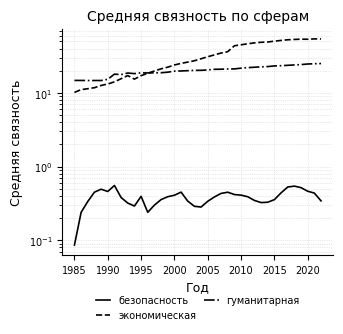

In [1364]:
# Настройки для ч/б печати
plt.rcParams.update({
    'font.size': 8,
    'axes.labelsize': 9,
    'axes.titlesize': 10,
    'legend.fontsize': 7,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'lines.linewidth': 1.2,
    'axes.linewidth': 0.8,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
})

# Список стилей линий – только различные пунктиры
line_styles = [
    '-',                      # сплошная
    '--',                     # штриховая
    '-.',                     # штрих-пунктирная
    ':',                      # пунктирная
    (0, (5, 2)),              # редкий пунктир
    (0, (3, 1, 1, 1)),        # точка-тире
    (0, (4, 2, 1, 2)),        # сложный пунктир
    (0, (1, 1)),              # очень частый пунктир
]

# Получаем список сфер в порядке их появления
spheres = av_connectivity_df['sphere'].unique()

# Компактная фигура с местом для легенды снизу
fig, ax = plt.subplots(figsize=(3.5, 3.6))

for i, sphere in enumerate(spheres):
    # Выбираем данные для конкретной сферы
    df_sphere = av_connectivity_df[av_connectivity_df['sphere'] == sphere]
    # Сортируем по году (на случай, если данные не упорядочены)
    df_sphere = df_sphere.sort_values('year')
    
    # Стиль линии
    style = line_styles[i % len(line_styles)]
    
    # Строим линию без маркеров
    ax.plot(
        df_sphere['year'], df_sphere['avg_connectivity'],
        linestyle=style,
        color='black',
        label=SUBSYSTEMS_RU[sphere]
    )

# Логарифмическая шкала по Y для отображения сильно различающихся величин
ax.set_yscale('log')

# Оформление осей
ax.set_title('Средняя связность по сферам')
ax.set_xlabel('Год')
ax.set_ylabel('Средняя связность')
ax.grid(True, which='both', linestyle=':', linewidth=0.5, color='lightgray')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Легенда размещена под графиком, горизонтально, без рамки
ax.legend(
    loc='upper center',          # отправная точка для bbox_to_anchor
    bbox_to_anchor=(0.5, -0.15), # сдвиг вниз от нижней границы осей
    ncol=2,                      # два столбца для компактности
    frameon=False,
    handlelength=1.5,
    columnspacing=0.8,
    borderaxespad=0.2
)

# Ручная настройка полей, чтобы легенда не обрезалась
plt.subplots_adjust(bottom=0.25)

# Сохранение с высоким разрешением
plt.savefig(f'../output/avg_connectivity_log{"_grey" if PLOT_GREY else ""}.png', dpi=300, bbox_inches='tight')
plt.show()

# Визуализация

## Центральность

In [1284]:
data = None# analysis[analysis['subsystem']=='economy']
#egos_top = data[data['rank']<=RANKMIN]['ego'].unique()
#data = data[data['ego'].isin(egos_top)]
#data = data[data['rank']<=MAXRANK]

economy


DEBUG:matplotlib.colorbar:locator: <matplotlib.ticker.AutoLocator object at 0x7f61f4563010>


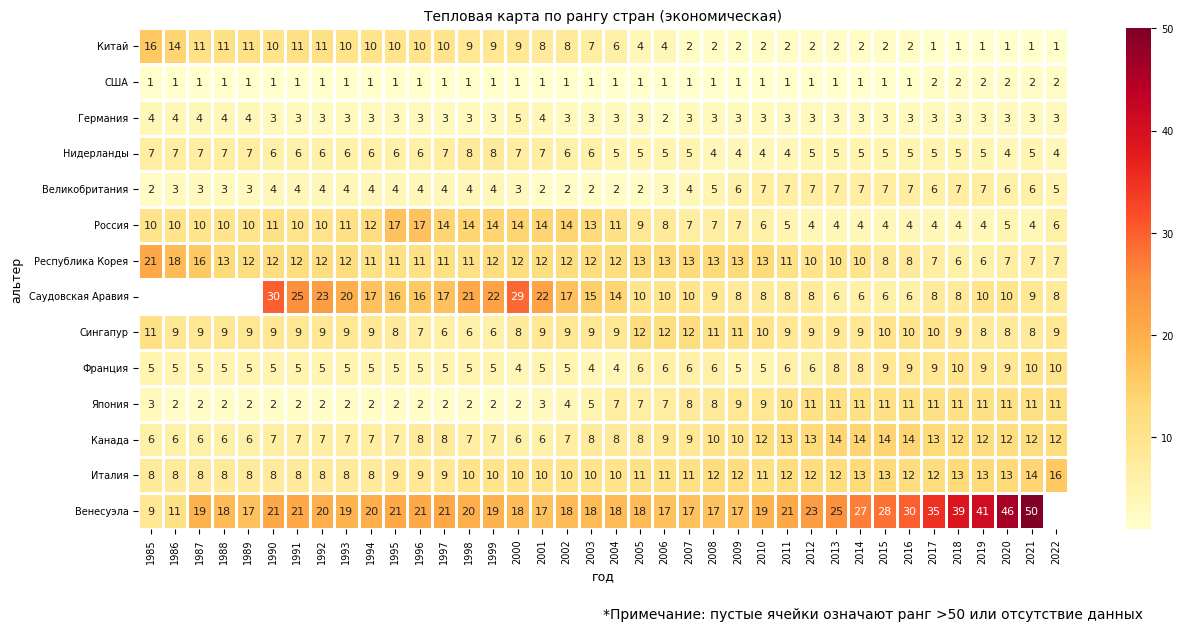

security


DEBUG:matplotlib.colorbar:locator: <matplotlib.ticker.AutoLocator object at 0x7f61a6dc0b90>


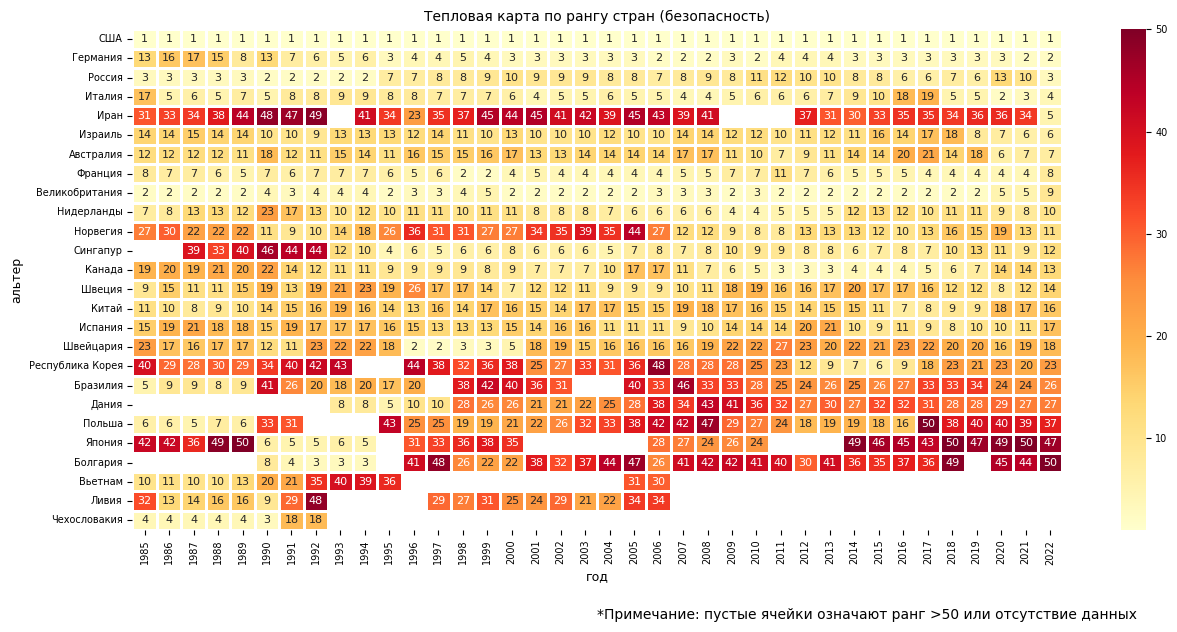

human


DEBUG:matplotlib.colorbar:locator: <matplotlib.ticker.AutoLocator object at 0x7f61d549cbd0>


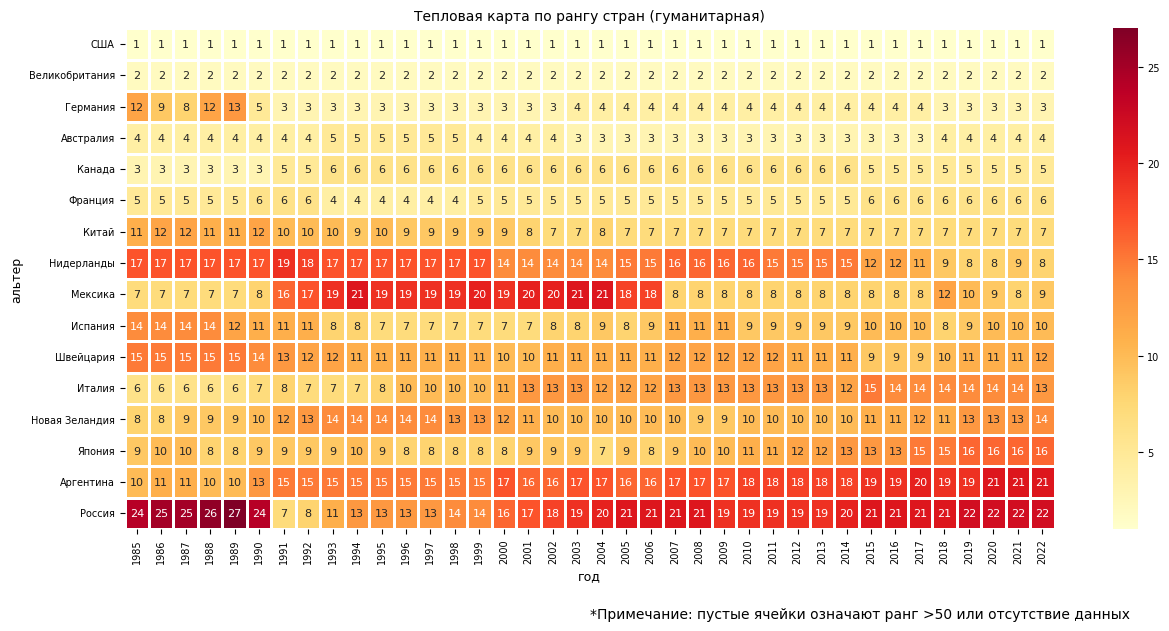

DEBUG:matplotlib.colorbar:locator: <matplotlib.ticker.AutoLocator object at 0x7f61d65bfb10>


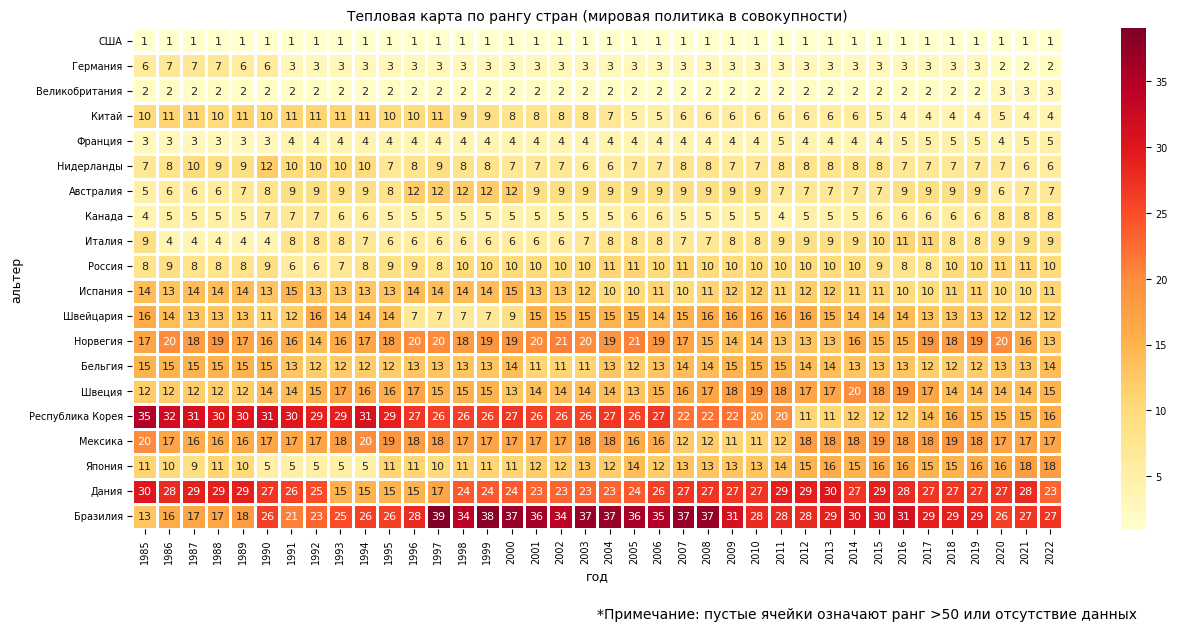

In [1368]:
for subsystem in SUBSYSTEMS:
    print(subsystem)
    visualize_sphere(analysis, sphere=subsystem, russify=True)

visualize_overall(status_combined, rankmin=15)

## Иерархичность

#### Центральность лидера

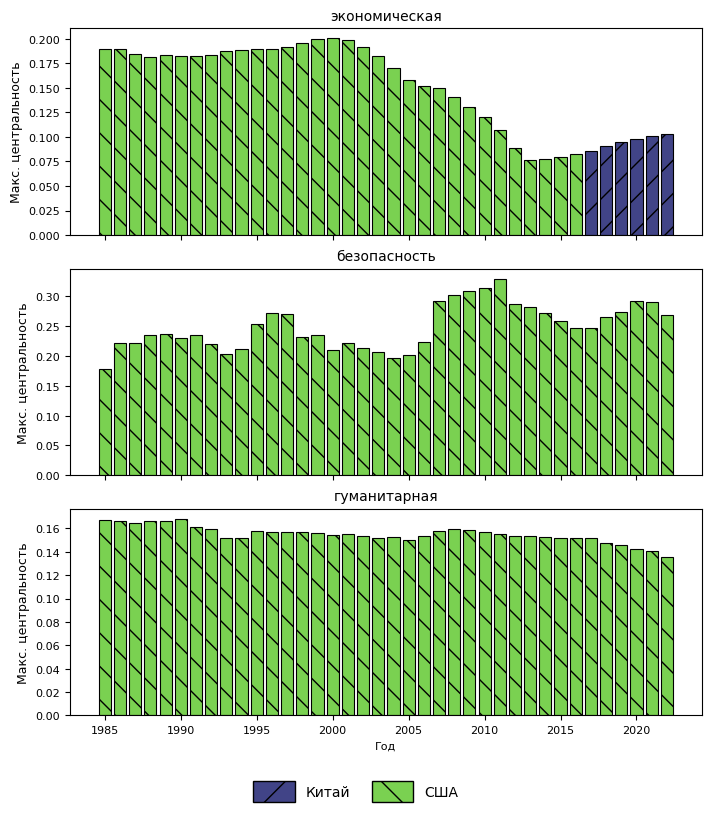

In [12]:
import matplotlib.patches as mpatches

# Шаг 1. Собираем все уникальные страны, встречающиеся хотя бы в одной подсистеме
# Шаг 1. Собираем все уникальные страны, встречающиеся хотя бы в одной подсистеме
all_countries = []
for subsystem in SUBSYSTEMS:
    df_sub = analysis[(analysis['subsystem'] == subsystem) & (analysis['rank'] <= 1)]
    for country in df_sub['ego'].unique():
        if country not in all_countries:
            all_countries.append(country)
all_countries.reverse()  # обратный порядок, как в исходном коде

# Шаг 2. Назначаем общие цвета (оттенки серого) и штриховки для всех стран
if PLOT_GREY:
    cmap = plt.get_cmap('Greys')
else:
    cmap = plt.get_cmap('viridis')
colors = cmap(np.linspace(0.2, 0.8, len(all_countries)))
hatch_patterns = ['/', '\\', '-', '+', 'x', 'o', 'O', '.', '*']

color_map = {country: colors[i] for i, country in enumerate(all_countries)}
hatch_map = {country: hatch_patterns[i % len(hatch_patterns)] for i, country in enumerate(all_countries)}

# Шаг 3. Создаём фигуру с вертикальным расположением подграфиков
fig, axes = plt.subplots(
    len(SUBSYSTEMS), 1,
    figsize=(7, 2.5 * len(SUBSYSTEMS)),  # компактная высота, ширина на всю страницу
    constrained_layout=True
)

# Шаг 4. Строим графики для каждой подсистемы
for ax, subsystem in zip(axes, SUBSYSTEMS):
    df = analysis[(analysis['subsystem'] == subsystem) & (analysis['rank'] <= 1)]

    for country in df['ego'].unique():
        df_country = df[df['ego'] == country]
        label = country
        if country == 'Russian Federation':
            label = 'Russian Federation (Soviet Union)'

        ax.bar(
            df_country['year'],
            df_country['centrality'],
            label=label,
            color=color_map[country],      # общий цвет для страны
            edgecolor='black',
            linewidth=0.8,
            hatch=hatch_map[country]       # общая штриховка
        )

    # Настраиваем каждый подграфик
    ax.set_title(SUBSYSTEMS_RU[subsystem], fontsize=10)
    ax.tick_params(axis='both', labelsize=8)
    ax.set_ylabel('Макс. центральность', fontsize=9)

    # Скрываем подписи оси X на всех графиках, кроме последнего
    if ax != axes[-1]:
        ax.tick_params(labelbottom=False)
        ax.set_xlabel('')
    else:
        ax.set_xlabel('Год', fontsize=8)

# Шаг 5. Создаём общую легенду для всей фигуры
handles = []
for country in all_countries:
    label = country
    if country == 'Russian Federation':
        label = 'Russian Federation (Soviet Union)'
    handle = mpatches.Patch(
        facecolor=color_map[country],
        edgecolor='black',
        hatch=hatch_map[country],
        label=label
    )
    handles.append(handle)

# Размещаем легенду внизу фигуры, с увеличенными элементами и достаточным отступом
fig.legend(
    handles=handles,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.08),          # ниже, чем подпись оси X
    ncol=min(3, len(all_countries)),     # до трёх столбцов
    fontsize=10,                         # увеличенный шрифт
    handlelength=3.0,                    # длиннее прямоугольники
    handleheight=2.0,                    # выше прямоугольники
    columnspacing=1.5,                   # расстояние между столбцами
    handletextpad=0.8,                   # расстояние между маркером и текстом
    frameon=False
)

# Шаг 6. Сохраняем с автоматической обрезкой полей и дополнительным запасом
plt.savefig(
    f'../output/leader_centrality_all{"_grey" if PLOT_GREY else ""}.png',
    dpi=300,
    bbox_inches='tight',
    pad_inches=0.1
)
plt.show()

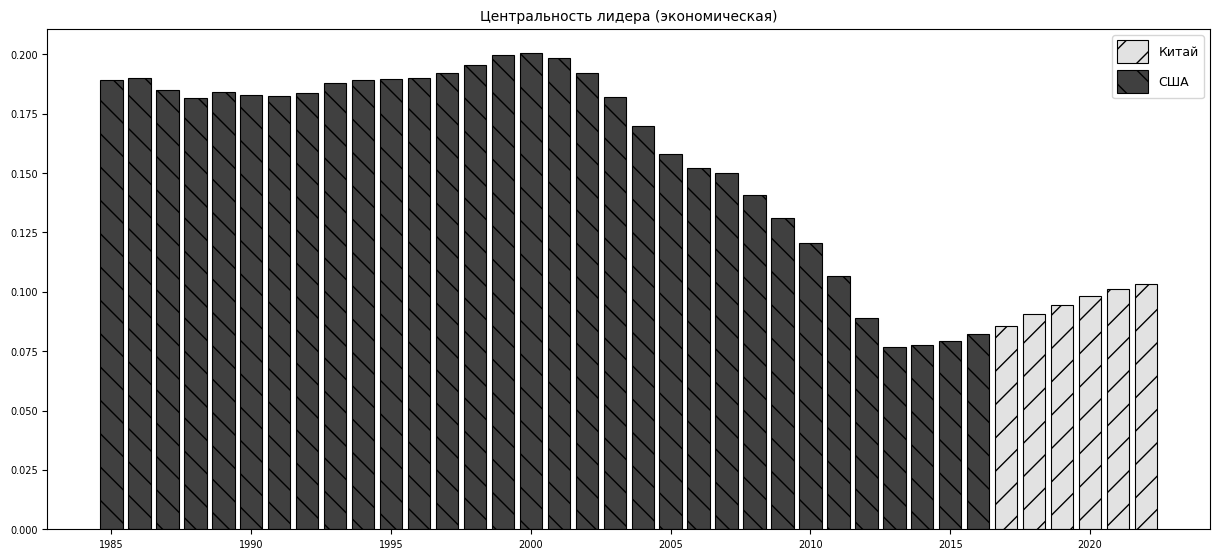

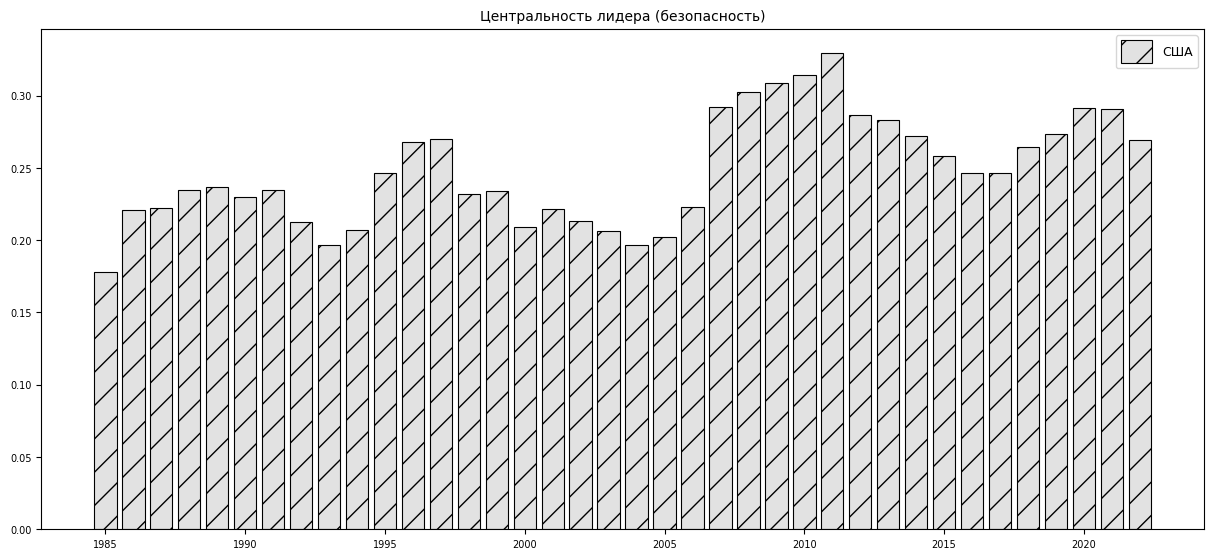

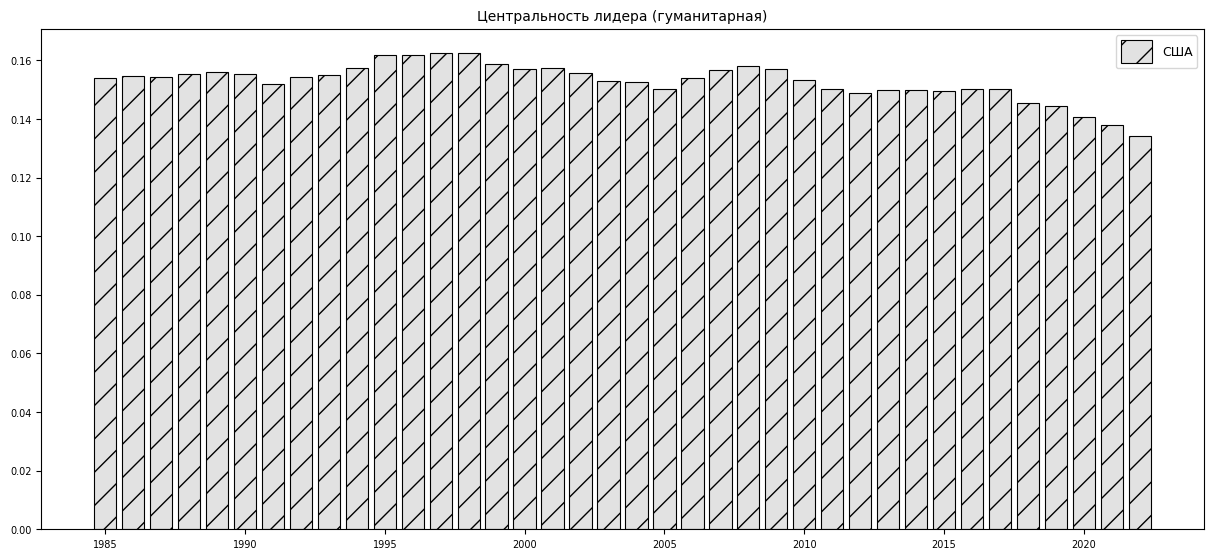

In [1262]:
for subsystem in SUBSYSTEMS:
    df = analysis[analysis['subsystem'] == subsystem]
    df = df[df['rank'] <= 1]
    
    plt.figure(figsize=(15, 6.5))
    countrynames = list(df['ego'].unique())
    countrynames.reverse()
    
    # Оттенки серого
    cmap = plt.get_cmap('Greys')
    colors = cmap(np.linspace(0.2, 0.8, len(countrynames)))
    
    # Список доступных штриховок (можно добавить ещё)
    hatch_patterns = ['/', '\\', '|', '-', '+', 'x', 'o', 'O', '.', '*']
    
    for i, countryname in enumerate(countrynames):
        df_country = df[df['ego'] == countryname]
        label = countryname
        if countryname == 'Russian Federation':
            label = 'Russian Federation (Soviet Union)'
        
        hatch = hatch_patterns[i % len(hatch_patterns)]
        
        plt.bar(df_country['year'], df_country['centrality'],
                label=label,
                color=colors[i],
                edgecolor='black',     # чёткая граница
                linewidth=0.8,         # небольшая рамка
                hatch=hatch)
    
    # Легенда с увеличенными прямоугольниками и читаемым размером шрифта
    plt.legend(handlelength=2.5, handleheight=2.5, fontsize=9)
    plt.title(f'Центральность лидера ({SUBSYSTEMS_RU[subsystem]})')
    plt.savefig(f'../output/{subsystem}_leader_centrality.png',
                dpi=300, bbox_inches='tight')
    plt.show()


#### Коэффициент демократичности

In [1204]:
# trophic coherence
## Moutsinas, G., Shuaib, C., Guo, W., & Jarvis, S. (2019). Graph hierarchy and spread of infections. arXiv preprint arXiv:1908.04358 
## https://www.nature.com/articles/s41598-021-93161-4
# https://github.com/shuaib7860/GraphHierarchy

In [18]:
# import GraphHierarchy as gh -- broken, adding a local fork instaed
from analysis import gh_fixed

In [19]:
def detect_hierarchy(subsystems):
    hierarchy_metrics = {}
    for subsystem in SUBSYSTEMS:
        hierarchy_metrics_sphere = {}
        for y in range (YEAR_START, YEAR_END+1):
            
            nodelist = list(subsystems[subsystem]['networks'][y].nodes())  # либо sorted(G.nodes()) или ваша предпочтительная упорядоченность
            # 2) Плотная numpy-матрица смежности для взвешенной матрицы по атрибуту 'weight':
            A_weighted = subsystems[subsystem]['networks'][y]#nx.to_numpy_array(subsystems[subsystem]['networks'][y], nodelist=nodelist, dtype=float, weight='weight')
            #print(A_weighted)
            #hierarchical_levels = gh.forward_hierarchical_levels(A_weighted, weight='value') #a weighted adjacency matrix, an N$\times$N dimensional array with the weights representing the forward hierarchical differences.
            #hierarchical_incoherence = gh.forward_hierarchical_incoherence(A_weighted, weight='value') # The function forward hierarchical incoherence returns the forward hierarchical differences sparse array and the associated mean and standard deviation of this distribution:
            #democracy_coef = gh.forward_democracy_coefficient(A_weighted, weight='value')
            #influence_centrality = gh.forward_influence_centrality(A_weighted, weight='value')

            hierarchical_levels = gh_fixed.backward_hierarchical_levels(A_weighted, weight='weight') #a weighted adjacency matrix, an N$\times$N dimensional array with the weights representing the forward hierarchical differences.
            hierarchical_incoherence = gh_fixed.backward_hierarchical_incoherence(A_weighted, weight='weight') # The function forward hierarchical incoherence returns the forward hierarchical differences sparse array and the associated mean and standard deviation of this distribution:
            democracy_coef = gh_fixed.backward_democracy_coefficient(A_weighted, weight='weight')
            influence_centrality = gh_fixed.backward_influence_centrality(A_weighted, weight='weight')
            influence_centrality = pd.DataFrame(list(zip(nodelist, influence_centrality)), columns=['ego','hierarchy_centrality']).sort_values('hierarchy_centrality')  # очень странная иерархия
            hierarchical_levels = pd.DataFrame(list(zip(nodelist, hierarchical_levels)), columns=['ego','hierarchical_levels']).sort_values('hierarchical_levels')  # очень странная иерархия
            hierarchy_metrics_sphere[y] = {'levels':hierarchical_levels,
                                    'incoherence':hierarchical_incoherence,
                                    'democracy_coef':democracy_coef,
                                    'influence_centrality':influence_centrality
                                   }
        hierarchy_metrics[subsystem]=hierarchy_metrics_sphere
        # Что-то не так с 2011 годом, надо разобраться
    return hierarchy_metrics

In [20]:
hierarchy_metrics = detect_hierarchy(subsystems)

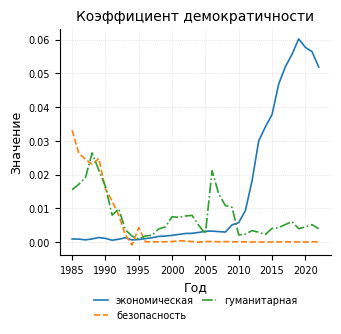

In [21]:
import matplotlib.pyplot as plt
import pandas as pd

# Настройки для ч/б печати
plt.rcParams.update({
    'font.size': 8,
    'axes.labelsize': 9,
    'axes.titlesize': 10,
    'legend.fontsize': 7,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'lines.linewidth': 1.2,
    'axes.linewidth': 0.8,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
})

# Список стилей линий – только различные пунктиры
line_styles = [
    '-',                      # сплошная
    '--',                     # штриховая
    '-.',                     # штрих-пунктирная
    ':',                      # пунктирная
    (0, (5, 2)),              # редкий пунктир
    (0, (3, 1, 1, 1)),        # точка-тире
    (0, (4, 2, 1, 2)),        # сложный пунктир
    (0, (1, 1)),              # очень частый пунктир
]

# Компактная фигура с местом для легенды снизу
fig, ax = plt.subplots(figsize=(3.5, 3.6))  # чуть выше, чтобы вместить легенду

for i, subsystem in enumerate(SUBSYSTEMS):
    # Извлекаем ряд данных
    series = pd.DataFrame.from_dict(hierarchy_metrics[subsystem]).loc['democracy_coef']
    
    # Выбираем стиль линии
    style = line_styles[i % len(line_styles)]
    
    # Строим линию без маркеров
    if PLOT_GREY:
        ax.plot(
            series.index, series.values,
            linestyle=style,
            color='black',
            label=SUBSYSTEMS_RU.get(subsystem, subsystem)
        )
    else:
        ax.plot(
            series.index, series.values,
            linestyle=style,
            label=SUBSYSTEMS_RU.get(subsystem, subsystem)
        )

# Оформление осей
ax.set_title('Коэффициент демократичности')
ax.set_xlabel('Год')
ax.set_ylabel('Значение')
ax.grid(True, linestyle=':', linewidth=0.5, color='lightgray')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Легенда размещена под графиком, горизонтально, без рамки
ax.legend(
    loc='upper center',          # отправная точка для bbox_to_anchor
    bbox_to_anchor=(0.5, -0.15), # сдвиг вниз от нижней границы осей
    ncol=2,                      # два столбца для компактности
    frameon=False,
    handlelength=1.5,
    columnspacing=0.8,
    borderaxespad=0.2
)

# Ручная настройка полей, чтобы легенда не обрезалась
plt.subplots_adjust(bottom=0.25)

# Сохранение с высоким разрешением
plt.savefig(f'../output/democracy_coef{"_grey" if PLOT_GREY else ""}.png', dpi=300, bbox_inches='tight')
plt.show()


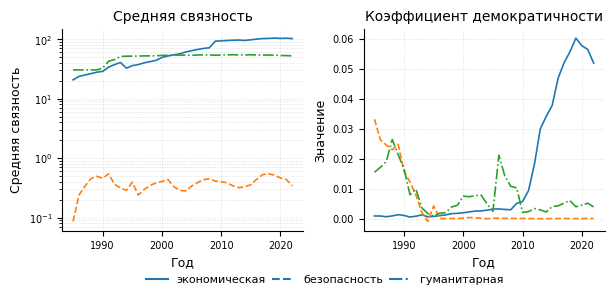

In [22]:
from matplotlib.lines import Line2D

# Настройки для ч/б печати
plt.rcParams.update({
    'font.size': 8,
    'axes.labelsize': 9,
    'axes.titlesize': 10,
    'legend.fontsize': 8,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'lines.linewidth': 1.2,
    'axes.linewidth': 0.8,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
})

# Стили линий – только различные пунктиры
line_styles = [
    '-',                      # сплошная
    '--',                     # штриховая
    '-.',                     # штрих-пунктирная
    ':',                      # пунктирная
    (0, (5, 2)),              # редкий пунктир
    (0, (3, 1, 1, 1)),        # точка-тире
    (0, (4, 2, 1, 2)),        # сложный пунктир
    (0, (1, 1)),              # очень частый пунктир
]

# Список сфер (подсистем)
spheres = SUBSYSTEMS  # например ['security', 'economy', ...]

if PLOT_GREY:
    color = 'black'
else:
    color = None
    
# Создаём фигуру с двумя подграфиками в ряд
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3.2))

# --- Левый график: средняя связность (логарифмическая шкала) ---
for i, sphere in enumerate(spheres):
    df_sphere = av_connectivity_df[av_connectivity_df['sphere'] == sphere].sort_values('year')
    style = line_styles[i % len(line_styles)]
    ax1.plot(
        df_sphere['year'], df_sphere['avg_connectivity'],
        linestyle=style,
        color=color
    )

ax1.set_yscale('log')
ax1.set_title('Средняя связность')
ax1.set_xlabel('Год')
ax1.set_ylabel('Средняя связность')
ax1.grid(True, which='both', linestyle=':', linewidth=0.5, color='lightgray')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# --- Правый график: коэффициент демократичности ---
for i, sphere in enumerate(spheres):
    series = pd.DataFrame.from_dict(hierarchy_metrics[sphere]).loc['democracy_coef']
    style = line_styles[i % len(line_styles)]
    ax2.plot(
        series.index, series.values,
        linestyle=style,
        color=color
    )

ax2.set_title('Коэффициент демократичности')
ax2.set_xlabel('Год')
ax2.set_ylabel('Значение')
ax2.grid(True, linestyle=':', linewidth=0.5, color='lightgray')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# --- Общая легенда (под графиками) ---
handles = []
for i, sphere in enumerate(spheres):
    style = line_styles[i % len(line_styles)]
    label = SUBSYSTEMS_RU.get(sphere, sphere) if 'SUBSYSTEMS_RU' in globals() else sphere
    # ВАЖНО: добавляем label в Line2D
    handle = Line2D([0], [0], color=color, linestyle=style, linewidth=1.5, label=label)
    handles.append(handle)

# Размещаем легенду под графиками
fig.legend(
    handles=handles,
    loc='lower center',            # привязка к нижнему центру
    bbox_to_anchor=(0.5, 0.05),   # сдвиг вниз, но не слишком большой
    ncol=min(3, len(spheres)),
    fontsize=8,
    handlelength=2.0,
    columnspacing=0.54,
    frameon=False
)

# Ручная настройка полей: уменьшаем зазор между графиками, оставляем место для легенды
plt.subplots_adjust(wspace=0.25, bottom=0.25)  # bottom увеличен для гарантии видимости легенды

# Сохранение с обрезкой полей
plt.savefig(
    f'../output/combined_horizontal{"_grey" if PLOT_GREY else ""}.png',
    dpi=300,
    bbox_inches='tight',
    pad_inches=0.2
)
plt.show()

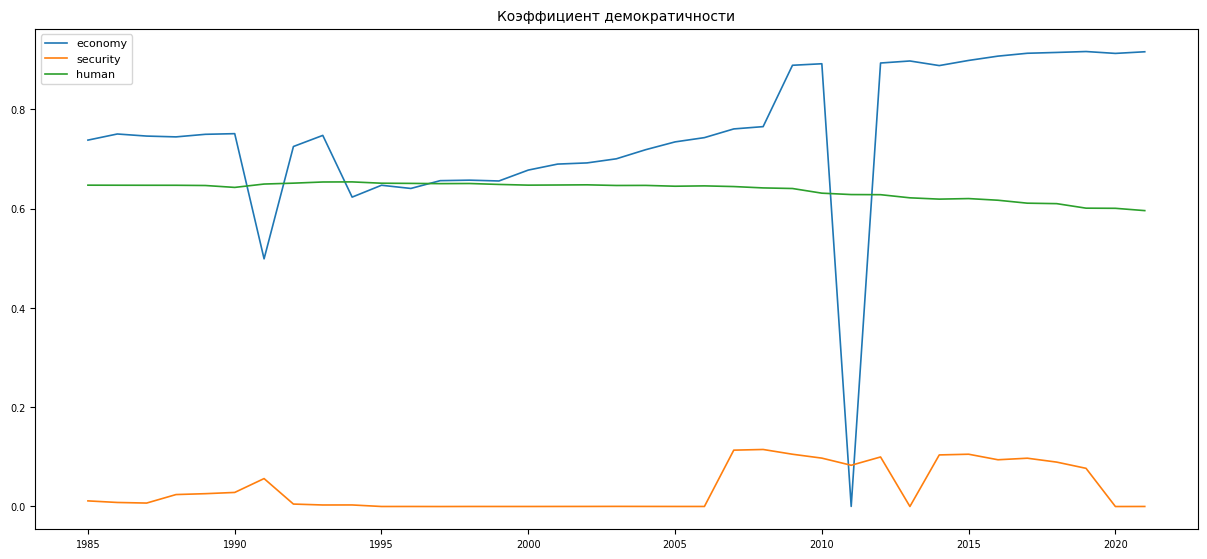

In [1379]:
plt.figure(figsize=(15, 6.5))
for subsystem in SUBSYSTEMS:
    plt.plot(pd.DataFrame.from_dict(hierarchy_metrics[subsystem]).loc['democracy_coef'], label=subsystem)
plt.legend()
plt.title('Коэффициент демократичности')
plt.savefig(f'../output/democracy_coef.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# 1 - проверяем, действительно ли этапы структурной перестройки выделены корректно
# 2 - анализ

#### Core-periphery analysis

In [1382]:
# https://github.com/skojaku/core-periphery-detection
import cpnet

ModuleNotFoundError: No module named 'cpnet'

In [1380]:
def detect_core_periphery(subsystems):
    core_periphery_metrics = {}
    #algorithm = cpnet.KM_config()  # плохой алгоритм, подобрать учитывающий веса
    algorithm = cpnet.Rombach()
    for subsystem in SUBSYSTEMS:
        core_periphery_metrics_sphere = {}
        for y in range (YEAR_START, YEAR_END):
            algorithm.detect(subsystems['security']['networks'][y])
            core_periphery_metrics_sphere[y] = {
                'pair_ids':algorithm.get_pair_id(),
                'coreness':algorithm.get_coreness()
            }
        core_periphery_metrics[subsystem]=core_periphery_metrics_sphere
        # Что-то не так с 2011 годом, надо разобраться
    return core_periphery_metrics

In [1381]:
core_periphery = detect_core_periphery(subsystems)
# странные результаты

NameError: name 'cpnet' is not defined

# Корреляции

In [762]:
correls = []
for c_a, c_b in list(product(analysis['ego'].unique(), analysis['ego'].unique())):
    print(c_a, c_b)
    if c_a == c_b: continue
    try:
        r = pearsonr(analysis[(analysis['ego']==c_a)&(analysis['subsystem']=='security')]['status'], analysis[(analysis['ego']==c_b)&(analysis['subsystem']=='security')]['status'])
    except Exception as E:
        print(E)
        r = [None, None]
    correls += [c_a, c_b, r[0], r[1]],

Kuwait Kuwait
Kuwait El Salvador
Kuwait Dominican Republic
Kuwait Sudan
Kuwait Somalia
Kuwait Papua New Guinea
Kuwait Sri Lanka
Kuwait Democratic Republic of the Congo
Kuwait Malawi
Kuwait Mauritania
Kuwait Hungary
Kuwait Bangladesh
Kuwait Romania
Kuwait Peru
Kuwait Kenya
Kuwait Haiti
Kuwait Argentina
Kuwait Saint Vincent and the Grenadines
Kuwait Venezuela (Bolivarian Republic of)
Kuwait Trinidad and Tobago
Kuwait Togo
Kuwait Chad
Kuwait Burundi
Kuwait Malaysia
Kuwait Côte d'Ivoire
Kuwait Tunisia
Kuwait United Arab Emirates
Kuwait Niger
Kuwait Lebanon
Kuwait Mongolia
Kuwait Djibouti
Kuwait Paraguay
Kuwait Comoros
Kuwait Germany
Kuwait Vanuatu
Kuwait Zambia
Kuwait Panama
Kuwait Malta
Kuwait Samoa
Kuwait Grenada
Kuwait Solomon Islands
Kuwait Rwanda
Kuwait Barbados
Kuwait Qatar
Kuwait Guatemala
Kuwait Equatorial Guinea
Kuwait Botswana
Kuwait Brunei Darussalam
Kuwait Costa Rica
Kuwait Bulgaria
Kuwait Mexico
Kuwait State of Palestine
Kuwait Liberia
Kuwait Cameroon
Kuwait Suriname
Kuwait Cy

In [774]:
res_df = pd.DataFrame(correls).dropna()
res_df.columns = ['ego', 'alter', 'r', 'p']
res_df.sort_values('r', inplace=True)
res_df.to_excel('../output/correlations_100825.xlsx')

In [773]:
res_df#[(res_df['p']<0.99)&res_df['r']<0.999].head()

,ego,alter,r,p
30955,United States,German Democratic Republic,-0.960732,1.239943e-21
28432,German Democratic Republic,United States,-0.960732,1.239943e-21
26677,Lao People's Democratic Republic,United States,-0.959444,2.193279e-21
30946,United States,Lao People's Democratic Republic,-0.959444,2.193279e-21
30577,South Africa,United States,-0.944696,5.164967e-19
...,...,...,...,...
7460,Samoa,State of Palestine,1.000000,0.000000e+00
7453,Samoa,Guatemala,1.000000,0.000000e+00
7451,Samoa,Barbados,1.000000,0.000000e+00
7482,Samoa,Jamaica,1.000000,0.000000e+00
